# BAO fits with desilike, at one bin width

**What it does.** For every sample of a `scripts/multidark_analysis.py` run (Full, Fil, NonFil, and Full
randomly diluted to N_Fil and to N_NonFil) it fits the monopole ξ₀(s) with desilike, DESI's BAO fitter,
using the monopoles of one bin width, chosen in the settings cell (`binsep`: 2.5 or 5.0 h⁻¹Mpc).

**Settings.** Everything you may want to change is in the next cell (magnitude cut `mag`, bin width
`binsep`, fit range `fit_range`, the Σ priors `Sigma_prior_sd` and `Sigma_free`, the samples, file
locations) and is printed by it. The covariance settings are read from `bao_fitting` (not repeated here)
and printed too. This text describes the method only: all numbers are in the cell outputs.

**Inputs:** ξ₀(s) and N from the monopole files of the run; the covariance `bf.gaussian_cov_pk`, built from
the measured (folded) auto-spectra of the same run (the spectra do not depend on the bin width, only the
covariance sum does); MultiDark-Planck cosmology (`bf.COSMO`).

**Three desilike fits per sample:**
* **α fit:** Gaussian prior on Σ, centred on Σ_th (the Zel'dovich prediction, section 1c) with width
  `Sigma_prior_sd`. Gives α (the BAO dilation parameter, desilike's `qiso`) and its 68% interval.
* **Σ fit:** flat prior on Σ over `Sigma_free`, α free. Gives the best-fit Σ with its 68% interval and
  Δχ²(Σ_th), both from the profile χ²(Σ) (section 2), and α with its 68% interval when Σ is left free
  ("α, Σ free"): the same α measurement without the Σ prior.
* **no-wiggle fit:** the same model without BAO. Δχ²_det = χ²(no-wiggle) − χ²(α fit, prior term included).

**Differences between samples (section 7):** Δα and ΔΣ for the pairs in `pairs`, from joint desilike
fits of the two samples with their joint covariance (cross terms included).

Not here: null-mock p-values. The random dilutions are fitted and listed in the
tables and printouts, but left out of the plots. A sample without a monopole file at `binsep` is skipped
with a message. Nothing is written to disk.

In [1]:
import os, sys, warnings, time, inspect
import numpy as np
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')

REPO = os.path.abspath(os.path.join(os.getcwd(), '..', '..'))   # notebook lives in notebooks/exploratory
sys.path.insert(0, os.path.join(REPO, 'src'))
import bao_fitting as bf

from cosmoprimo.fiducial import Cosmology
from desilike.theories.galaxy_clustering import (BAOPowerSpectrumTemplate,
                                                 DampedBAOWigglesTracerCorrelationFunctionMultipoles)
from desilike.observables.galaxy_clustering import TracerCorrelationFunctionMultipolesObservable
from desilike.likelihoods import ObservablesGaussianLikelihood
from desilike.profilers import MinuitProfiler

DESI, DATA = '#eb6834', '0.15'
FREE = '#2a78d6'                    # colour of the Sigma-free fit (alpha with Sigma left free)
SCOL = {'Full': '0.15', 'Fil': '#6250d6', 'NonFil': '#1baf7a', 'Full dil nFil': '#eda100', 'Full dil nNonFil': '#e87ba4'}   # colour of each sample
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.25, 'lines.linewidth': 1.6})

# ---------------- settings (change here only) ----------------
mag = -20.8                         # absolute-magnitude cut of the run (part of the file names)
binsep = 2.5                        # bin width of the monopoles to fit [h^-1 Mpc]: 2.5 or 5.0
mono_sep = (5.0, 150.0)             # separation range of the monopole files [h^-1 Mpc] (in their names)
split_name = 'dist_fil'             # split variable(s) of the run (in the spectra file name)
fit_range = (50., 150.)             # [h^-1 Mpc]
Sigma_prior_sd = 6.0                # width of the Gaussian Sigma prior of the alpha fit (centred on Sigma_th)
Sigma_free = (0., 16.)              # flat prior of the Sigma fit
Sigma_step = 0.5                    # [h^-1 Mpc] grid step of the profile chi2(Sigma) (Sigma interval, section 2)
# differences between samples (section 7): Delta = A - B for each (A, B); chosen before looking at the results
pairs = [('Fil', 'Full dil nFil'), ('NonFil', 'Full dil nNonFil'), ('Fil', 'NonFil'), ('Fil', 'Full'), ('NonFil', 'Full')]
dalpha_max, dalpha_step = 0.12, 0.005   # profile chi2(Delta alpha) on [-dalpha_max, dalpha_max]
dSigma_step = 1.0                   # [h^-1 Mpc] profile chi2(Delta Sigma) on [-Sigma_free[1], Sigma_free[1]]
k_bao = 0.3                         # [h/Mpc] marked as the end of the BAO information in the plots (section 1c)

# sample -> <bin_desc> of the monopole files (= label in the spectra file).  The random dilutions of
# Full are added below: their label contains N, so they are looked up in the spectra file.
samples = {'Full': 'full',
           'Fil': '0.0leqd_mathrmfilleq3.0',
           'NonFil': '10.0leqd_mathrmfilleq100.0'}
dilution_of = ('Fil', 'NonFil')     # add 'Full dil n<sample>' for these samples, if in the spectra file
plot_samples = ['Full', 'Fil', 'NonFil']      # the dilutions appear in tables only
# -------------------------------------------------------------
MONO = os.path.join(REPO, 'data/processed/monopoles/box')
pk_file = os.path.join(REPO, f'data/processed/pk/box/pk_XISMU_box_mag{mag:.1f}_{split_name}.npz')

def monopole_file(key):
    # file written by multidark_analysis.py (multidark_correlation.get_save_filename); None if missing
    f = os.path.join(MONO, f'mag={mag:.1f}_sep={mono_sep[0]:.1f}-{mono_sep[1]:.1f}_binsep={binsep:.1f}_{key}.npz')
    return f if os.path.exists(f) else None

C0 = bf.COSMO
cosmo = Cosmology(h=C0['H0'] / 100., omega_b=C0['ombh2'], omega_cdm=C0['omch2'], A_s=C0['As'], n_s=C0['ns'],
                  m_ncdm=[] if C0.get('mnu', 0.06) == 0 else [C0['mnu']], engine='camb')
lin = bf.linear_theory()
k, P_w, P_nw = bf.generate_templates(lin=lin)
T = bf.BAOTemplate(k, P_w, P_nw, lin)
Sigma_th = bf.sigma_nl_theory(lin)['Sigma_mono']
spec = bf.load_spectra(pk_file)

for lab in dilution_of:
    n = spec['n_gal'][spec['labels'].index(samples[lab])]
    dil = [l for l, nn in zip(spec['labels'], spec['n_gal']) if l.startswith('FullrandomN-') and nn == n]
    if dil:
        samples[f'Full dil n{lab}'] = dil[0]

# covariance and bias settings, read from bao_fitting so the plots always show what the code does
defaults = lambda f: {n: p.default for n, p in inspect.signature(f).parameters.items()
                      if p.default is not inspect.Parameter.empty}
cov_set, kmax_cov = defaults(bf.spectrum_for_cov), defaults(bf.gaussian_cov_pk)['kmax']
k_lo, k_hi, k_use = cov_set['k_lo'], cov_set['k_hi'], spec['kmax']   # k_use = end of the measured spectrum
b_set = defaults(bf.estimate_bias_independent)
bias_range = b_set['ranges'][b_set['primary']]

print(f"magnitude cut {mag};  bin width {binsep} h^-1 Mpc;  fit range {fit_range} h^-1 Mpc;  "
      f"monopole files cover {mono_sep}")
print(f"alpha fit: Sigma ~ N({Sigma_th:.2f}, {Sigma_prior_sd:g}) [Sigma_th = Zel'dovich prediction];  "
      f"Sigma fit: flat {Sigma_free}, profile chi2(Sigma) in steps of {Sigma_step:g}")
print(f"covariance: bias from {bias_range} h^-1 Mpc;  P_cov = b^2 P_lin + N below k_lo = {k_lo}, measured above "
      f"k_hi = {k_hi} (N from k in {cov_set['n_win']}), measured spectrum up to k = {k_use:.3f} "
      f"({spec['n_fold']} foldings, each level to {spec['kuse_frac']} of its Nyquist), constant excess above, "
      f"modes summed to k = {kmax_cov}")
print(f"spectra file: {os.path.basename(pk_file)}")
print("differences (A - B): " + ", ".join(f"{a} - {b}" for a, b in pairs)
      + f";  grids: Delta alpha step {dalpha_step:g} on +-{dalpha_max:g}, Delta Sigma step {dSigma_step:g}")
print("samples: " + ", ".join(f"{l} = '{k_}'" for l, k_ in samples.items()))

magnitude cut -20.8;  bin width 2.5 h^-1 Mpc;  fit range (50.0, 150.0) h^-1 Mpc;  monopole files cover (5.0, 150.0)
alpha fit: Sigma ~ N(7.78, 6) [Sigma_th = Zel'dovich prediction];  Sigma fit: flat (0.0, 16.0), profile chi2(Sigma) in steps of 0.5
covariance: bias from (40, 70) h^-1 Mpc;  P_cov = b^2 P_lin + N below k_lo = 0.02, measured above k_hi = 0.025 (N from k in (0.1, 0.2)), measured spectrum up to k = 2.893 (2 foldings, each level to 0.6 of its Nyquist), constant excess above, modes summed to k = 3.0
spectra file: pk_XISMU_box_mag-20.8_dist_fil.npz
differences (A - B): Fil - Full dil nFil, NonFil - Full dil nNonFil, Fil - NonFil, Fil - Full, NonFil - Full;  grids: Delta alpha step 0.005 on +-0.12, Delta Sigma step 1
samples: Full = 'full', Fil = '0.0leqd_mathrmfilleq3.0', NonFil = '10.0leqd_mathrmfilleq100.0', Full dil nFil = 'FullrandomN-1043082r20261016', Full dil nNonFil = 'FullrandomN-2176035r20261016'


## 1. Data and covariance

For each sample: N, the number of bins in the fit range, and the bias b used in the covariance (fitted
over `bias_range`, printed above; it only enters the covariance below k_lo). Then the monopoles with their
errors √diag(C) (top) and the errors alone (bottom).

Full               N =  4999875   40 bins in fit range   b(cov) = 0.978
Fil                N =  1043082   40 bins in fit range   b(cov) = 1.384
WARNING bias estimate unstable across ranges: (30, 60): 0.607, (40, 70): 0.722, (35, 75): 0.674  -> check the monopole at 30-75 h^-1 Mpc; the covariance scales as b^4 below k_lo of spectrum_for_cov
NonFil             N =  2176035   40 bins in fit range   b(cov) = 0.722
Full dil nFil      N =  1043082   40 bins in fit range   b(cov) = 0.961
Full dil nNonFil   N =  2176035   40 bins in fit range   b(cov) = 0.967


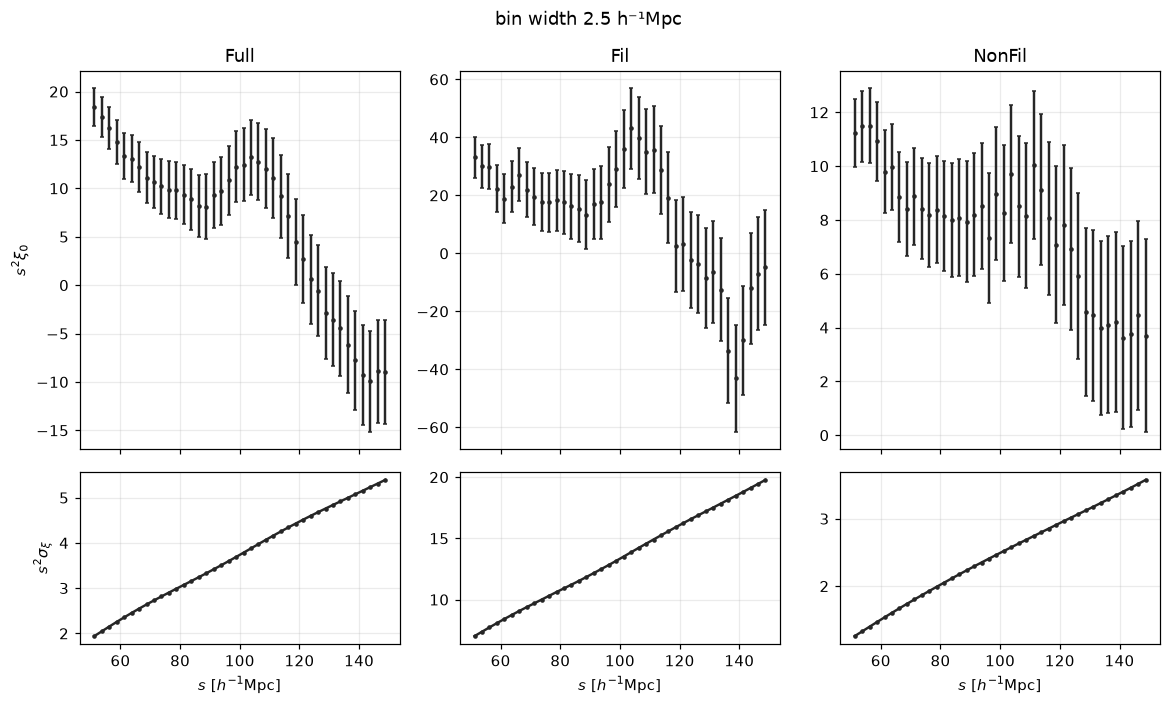

In [2]:
data = {}
for lab, key in samples.items():
    f = monopole_file(key)
    if f is None:
        print(f"SKIP {lab}: no monopole file at bin width {binsep} "
              f"(run scripts/multidark_analysis.py with mag_max = {mag}, bin_size_2d = {binsep})")
        continue
    s, xi, n_gal = bf.load_monopole(f)
    edges = bf.edges_from_centres(s)
    assert edges[0] <= fit_range[0] and edges[-1] >= fit_range[1], \
        f"{lab}: monopole covers {edges[0]}-{edges[-1]}, fit_range is {fit_range}"
    i_spec = spec['labels'].index(key)
    assert int(spec['n_gal'][i_spec]) == n_gal, f"{lab}: N differs from the spectra file"
    b = bf.estimate_bias_independent(s, xi, edges, n_gal / bf.L_BOX**3, T)['b']
    C = bf.gaussian_cov_pk(edges, spec, [i_spec], [b], lin)
    m = (s >= fit_range[0]) & (s <= fit_range[1])
    data[lab] = dict(s=s, xi=xi, edges=edges, C=C, sig=np.sqrt(np.diag(C)), m=m, n_gal=n_gal, b=b)
    print(f"{lab:<18} N = {n_gal:>8d}   {m.sum():>2d} bins in fit range   b(cov) = {b:.3f}")

labs = list(data)                                    # all samples (tables)
labs_p = [l for l in labs if l in plot_samples]      # plotted samples
fig, axes = plt.subplots(2, len(labs_p), figsize=(3.6 * len(labs_p), 6.5), sharex=True,
                         gridspec_kw=dict(height_ratios=(2.2, 1)), squeeze=False)
for j, lab in enumerate(labs_p):
    d = data[lab]; s, m = d['s'], d['m']
    axes[0, j].errorbar(s[m], s[m]**2 * d['xi'][m], yerr=s[m]**2 * d['sig'][m], fmt='.', ms=4, capsize=1.5,
                        color=DATA)
    axes[1, j].plot(s[m], s[m]**2 * d['sig'][m], '.-', ms=4, color=DATA)
    axes[0, j].set_title(lab); axes[1, j].set_xlabel(r'$s\ [h^{-1}{\rm Mpc}]$')
axes[0, 0].set_ylabel(r'$s^2\xi_0$'); axes[1, 0].set_ylabel(r'$s^2\sigma_\xi$')
fig.suptitle(f'bin width {binsep:g} h⁻¹Mpc'); fig.tight_layout(); plt.show()

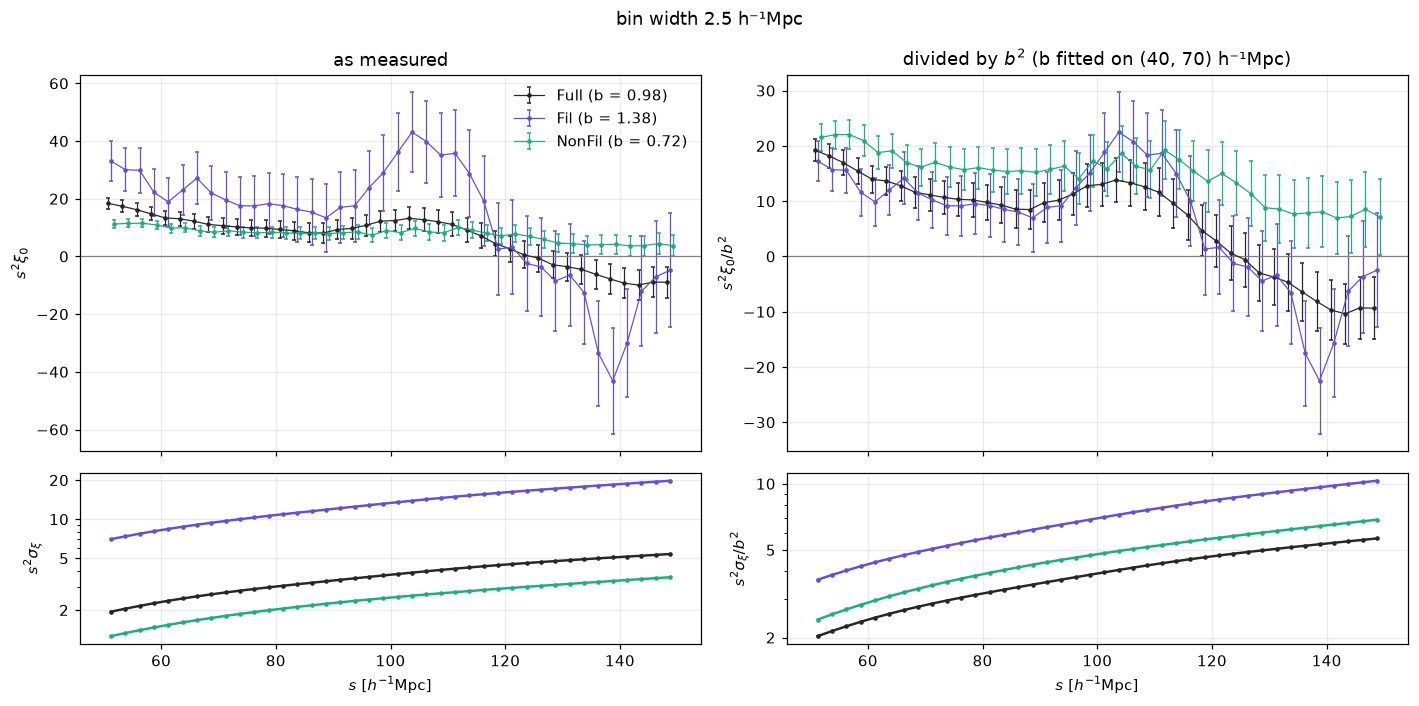

In [3]:
# the same monopoles and errors as above, all samples in one panel: as measured (left) and divided by b^2 (right),
# b = the covariance bias printed above (fitted on bias_range, see bf.estimate_bias_independent)
import matplotlib.ticker as mticker
dodge = 0.2 * binsep * (np.arange(len(labs_p)) - (len(labs_p) - 1) / 2)   # small s offsets so error bars don't overlap
fig, axes = plt.subplots(2, 2, figsize=(13, 6.5), sharex=True, gridspec_kw=dict(height_ratios=(2.2, 1)))
for j, scaled in enumerate((False, True)):
    for lab, ds in zip(labs_p, dodge):
        d = data[lab]; s, m = d['s'], d['m']
        f = 1 / d['b']**2 if scaled else 1.0
        axes[0, j].errorbar(s[m] + ds, f * s[m]**2 * d['xi'][m], yerr=f * s[m]**2 * d['sig'][m], fmt='.-', ms=4,
                            lw=0.8, capsize=1.5, color=SCOL[lab], label=f"{lab} (b = {d['b']:.2f})")
        axes[1, j].plot(s[m], f * s[m]**2 * d['sig'][m], '.-', ms=4, color=SCOL[lab])
    axes[0, j].axhline(0, color='0.5', lw=0.8)
    axes[1, j].set_yscale('log'); axes[1, j].set_xlabel(r'$s\ [h^{-1}{\rm Mpc}]$')
    axes[1, j].yaxis.set_major_locator(mticker.LogLocator(subs=(1, 2, 5)))
    axes[1, j].yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'{v:g}'))
    axes[1, j].yaxis.set_minor_formatter(mticker.NullFormatter())
axes[0, 0].set_title('as measured'); axes[0, 1].set_title(f'divided by $b^2$ (b fitted on {bias_range} h⁻¹Mpc)')
axes[0, 0].set_ylabel(r'$s^2\xi_0$'); axes[0, 1].set_ylabel(r'$s^2\xi_0/b^2$')
axes[1, 0].set_ylabel(r'$s^2\sigma_\xi$'); axes[1, 1].set_ylabel(r'$s^2\sigma_\xi/b^2$')
axes[0, 0].legend(frameon=False)
fig.suptitle(f'bin width {binsep:g} h⁻¹Mpc'); fig.tight_layout(); plt.show()

## 1b. The measured power spectra, and what "excess noise" means

The covariance is built from these spectra (one auto-spectrum per sample, file `pk_file`). Colours here =
samples (not codes). The k values named below (k_lo, k_hi, k_use, k_bao) are printed in the setup cell.

**Left:** P(k) of each sample (solid), shot noise not subtracted. Dotted: b²P_lin(k), the linear-theory
prediction with the sample's bias. Dashed horizontal: the Poisson shot noise 1/n̄. For a Poisson sample of a
linear density field, P = b²P_lin + 1/n̄: the curve would follow the dotted line at low k and flatten onto
the dashed line at high k.

**Right:** the "excess" [P(k) − b²P_lin(k)] · n̄: everything in the measured power that linear theory does
not explain, in units of Poisson shot noise. For a Poisson sample of a linear field it would be exactly 1
at every k. Above 1 means extra power: non-linear clustering of small groups (galaxies sharing haloes) and,
for Fil, any extra clumpiness from how DisPerSE selects filament galaxies. In the covariance it acts like
extra noise, which is why we call it "excess noise". The spectra are measured up to k_use by
folding the box (`multidark_power.measure_spectra`): the positions are wrapped into a box of side L/2^f and
measured on the same grid, which gives exactly the modes of the full box that fit in L/2^f, and
P(k) = 8^f P_folded(k). Each fold level is used up to `kuse_frac` of its own Nyquist frequency, so no part
of the plotted spectrum is near a grid limit. The short dashed lines show the constant value the covariance
assumes beyond k_use (and up to infinite k), the measured excess averaged just below k_use.
Vertical dotted lines: k_lo (below it the covariance uses b²P_lin + N), the start of each fold level, and k_use.
Shaded: k < k_bao (section 1c).

Below k_hi the measured spectrum is used directly by the covariance, so any excess there (noise or extra
clustering) is not an assumption; the assumption is only the dashed tail. The printed table also lists the
two random dilutions: "Full dil nFil" has the same n̄ as Fil but randomly chosen galaxies, so comparing it
with Fil separates the effect of *which* galaxies are selected from the effect of *how many*.

sample               1/nbar  excess x nbar at k = 0.15, 0.3, 0.6, 1, 1.5, 2, 2.8   | value assumed above 2.89
Full                    200   2.07  2.54  2.12  1.76  1.51  1.38  1.25   |  1.26
Fil                     959  16.22 10.87  6.16  3.54  2.41  1.95  1.61   |  1.62
NonFil                  460   4.74  2.67  1.79  1.45  1.28  1.21  1.15   |  1.15
Full dil nFil           959   1.36  1.36  1.25  1.16  1.11  1.09  1.06   |  1.06
Full dil nNonFil        460   1.65  1.72  1.50  1.34  1.22  1.17  1.11   |  1.12


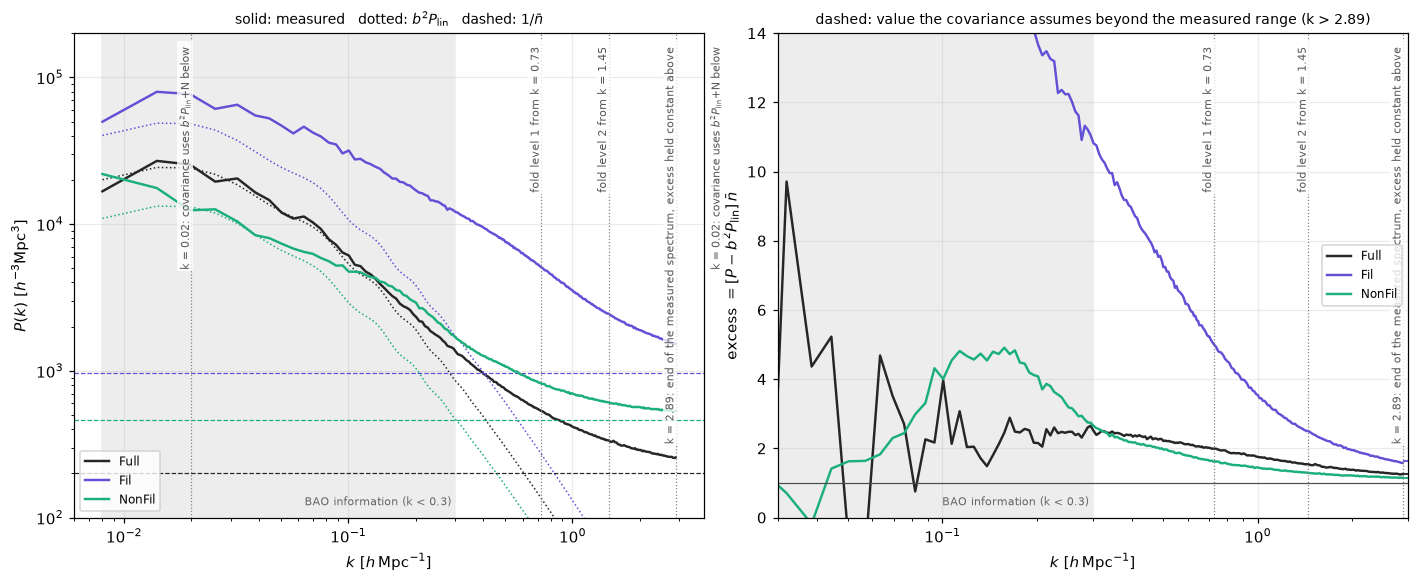

In [4]:
kk = spec['k']
k_fold = [kk[spec['level'] == f][0] for f in range(1, spec['n_fold'] + 1)]   # start of each fold level
k_print = (0.15, 0.3, 0.6, 1.0, 1.5, 2.0, 2.8)
Plin = lambda x: np.exp(np.interp(np.log(x), np.log(lin['kh']), np.log(lin['pk'])))
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 5.4))
print(f"{'sample':<18}{'1/nbar':>9}  excess x nbar at k = " + ", ".join(f"{x:g}" for x in k_print)
      + f"   | value assumed above {k_use:.2f}")
for lab, key in samples.items():
    if lab not in data: continue
    i = spec['labels'].index(key); nbar = spec['n_gal'][i] / bf.L_BOX**3; b = data[lab]['b']; c = SCOL[lab]
    P = spec['P'][i, i]
    ex = (P - b**2 * Plin(kk)) * nbar
    _, ex_tail = bf.spectrum_for_cov(spec, i, i, b, b, lin, np.array([0.5]))
    if lab in plot_samples:
        a1.loglog(kk, P, color=c, label=lab)
        a1.loglog(kk, b**2 * Plin(kk), color=c, ls=':', lw=1)
        a1.axhline(1 / nbar, color=c, ls='--', lw=0.8)
        a2.semilogx(kk, ex, color=c, label=lab)
        a2.hlines(ex_tail * nbar, k_use, kmax_cov, color=c, ls='--', lw=1.2)
    at = lambda x: np.interp(x, kk, ex)
    print(f"{lab:<18}{1/nbar:>9.0f}  " + " ".join(f"{at(x):5.2f}" for x in k_print) + f"   | {ex_tail * nbar:5.2f}")
vlines = ((k_lo, f'k = {k_lo}: covariance uses $b^2P_{{\\rm lin}}$+N below'),
          *[(x, f'fold level {f + 1} from k = {x:.2f}') for f, x in enumerate(k_fold)],
          (k_use, f"k = {k_use:.2f}: end of the measured spectrum, excess held constant above"))
for a in (a1, a2):
    a.axvspan(kk[0], k_bao, color='0.93', zorder=0)
    a.text(k_bao, 0.02, f'BAO information (k < {k_bao}) ', transform=a.get_xaxis_transform(), ha='right', va='bottom',
           fontsize=7, color='0.4')
    for x, txt in vlines:
        a.axvline(x, color='0.5', ls=':', lw=0.8)
        a.text(x, 0.98, txt + ' ', transform=a.get_xaxis_transform(), rotation=90, ha='right', va='top',
               fontsize=7, color='0.35', bbox=dict(fc='white', ec='none', alpha=0.8, pad=1))
    a.set_xlabel(r'$k\ [h\,{\rm Mpc}^{-1}]$')
a1.set_ylabel(r'$P(k)\ [h^{-3}{\rm Mpc}^3]$'); a1.set_ylim(1e2, 2e5); a1.legend(fontsize=8, loc='lower left')
a1.set_title('solid: measured   dotted: $b^2P_{\\rm lin}$   dashed: $1/\\bar n$', fontsize=9)
a2.axhline(1, color='0.3', lw=0.8); a2.set_xlim(0.03, kmax_cov); a2.set_ylim(0, 14)
a2.set_ylabel(r'excess $=[P - b^2P_{\rm lin}]\,\bar n$'); a2.legend(fontsize=8, loc='center right')
a2.set_title(f"dashed: value the covariance assumes beyond the measured range (k > {k_use:.2f})", fontsize=9)
fig.tight_layout(); plt.show()

### The spectrum that actually enters the covariance

The plots above show the *measured* spectra. The covariance uses a patched version, P_cov(k), built by
`bf.spectrum_for_cov` and evaluated on the box's discrete modes (|k| = 2π|n|/L) up to `kmax_cov`. The
settings named here are arguments of `spectrum_for_cov` / `gaussian_cov_pk`; their values are printed in
the setup cell.

| k range | P_cov(k) | why |
|---|---|---|
| k < k_lo | b²P_lin(k) + N_low, with N_low = mean excess over `n_win` | few modes, measurement noisy |
| k_lo – k_hi | linear blend of the two | smooth transition |
| k_hi – k_use | the measured P(k) (folded at high k) | well measured |
| k_use – kmax_cov | b²P_lin(k) + N_tail, N_tail = mean excess just below k_use | beyond the measurement |
| > kmax_cov | constant N_tail (added analytically, Parseval) | — |

k_use is the end of the measured spectrum, set in `multidark_analysis.py` by `pk_ngrid`, `pk_n_fold` and
`pk_kuse_frac`: fold level f reaches kuse_frac · π ng 2^f / L. `kuse_frac` < 1 because near each level's
Nyquist frequency the measurement is affected by aliasing and the grid-assignment window.

Top row: measured spectrum (grey) and P_cov (colour) for each sample; shading marks the regions.
Bottom row: P_cov / P_measured where both exist. Ratios ≠ 1 show where the covariance is not using the
measurement.

**Why the measured P(k) is not used below k_lo.** The box contains only a few long-wavelength modes.
The power in each single mode fluctuates randomly by about 100% of its mean (that is the Gaussian property
the covariance formula itself uses), and the measured P(k) in a k bin is the average over the modes in that
bin, so its scatter is about 1/√N for N independent modes (k and −k are the same mode, so N is half the
number of grid modes). The cell below counts them from the spectra file.

The covariance needs the *expected* P(k) (the average over many universes), not this box's particular
random values, and P enters it squared, so a fractional fluctuation ε in P becomes ≈ 2ε in the covariance.
Where the scatter is large (below k_lo) the smooth model b²P_lin + N is used; above k_hi the measurement is
used directly; in between the two are blended. The model only enters where the data cannot pin down the
average.

In [5]:
nm = spec['nmodes']
print(f"k bin width = {kk[1] - kk[0]:.4f} h/Mpc")
print(f"{'k':>8}{'grid modes':>12}{'independent':>13}{'scatter 1/sqrt(N)':>19}")
for kx in sorted({0.008, 0.02, 0.04, k_lo, k_hi, k_bao}):
    i = np.argmin(abs(kk - kx))
    print(f"{kk[i]:>8.4f}{nm[i]:>12.0f}{nm[i] / 2:>13.0f}{1 / np.sqrt(nm[i] / 2):>19.3f}")

k bin width = 0.0060 h/Mpc
       k  grid modes  independent  scatter 1/sqrt(N)
  0.0080          18            9              0.333
  0.0197          98           49              0.143
  0.0255         210          105              0.098
  0.0385         450          225              0.067
  0.3016       29066        14533              0.008


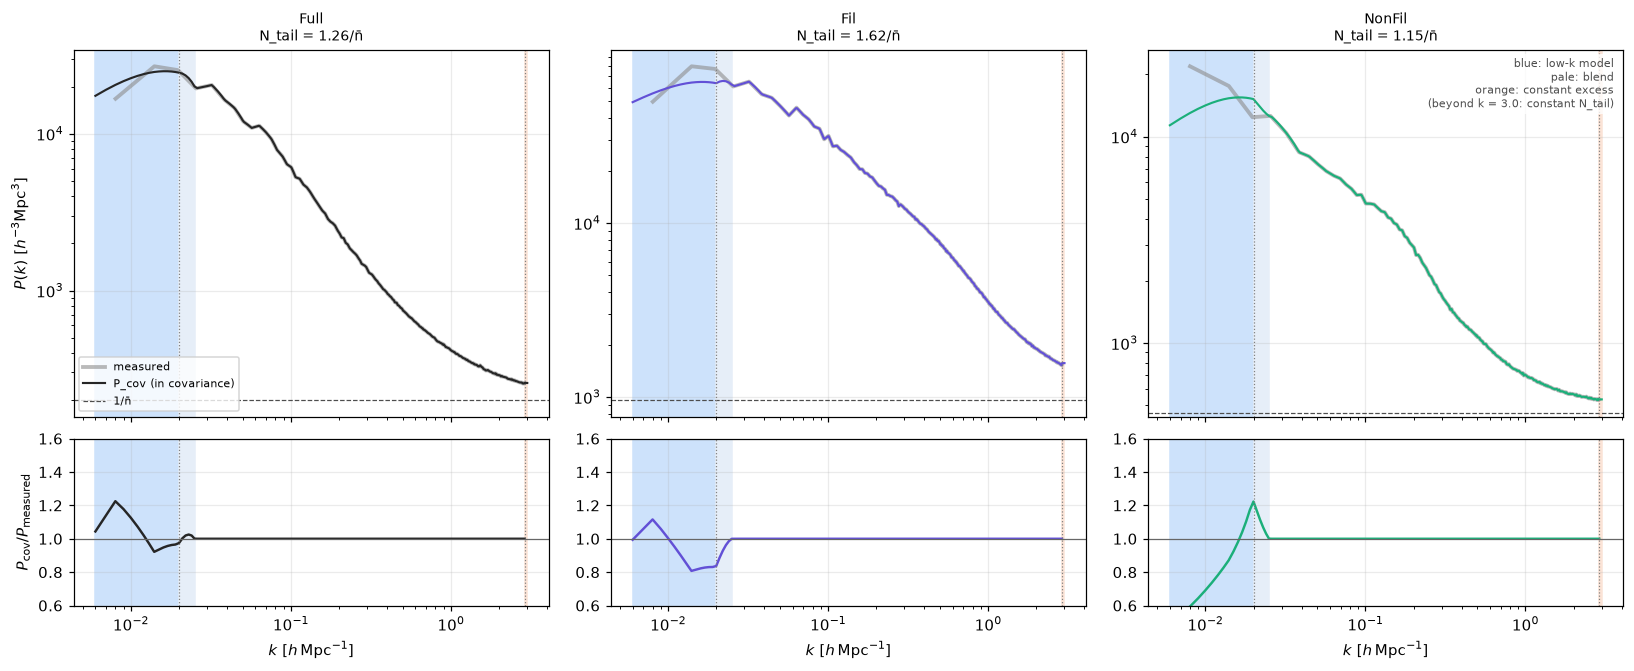

In [6]:
kgrid = np.linspace(0.006, kmax_cov, 3000)
labs_s = [l for l in plot_samples if l in data]
fig, axes = plt.subplots(2, len(labs_s), figsize=(5 * len(labs_s), 6.2), sharex=True,
                         gridspec_kw=dict(height_ratios=(2.2, 1)), squeeze=False)
regions = ((0.006, k_lo, '#cde2fb'), (k_lo, k_hi, '#e6eef8'), (k_use, kmax_cov, '#fbe3d6'))
for j, lab in enumerate(labs_s):
    key = samples[lab]; i = spec['labels'].index(key); b = data[lab]['b']; c = SCOL[lab]
    Pcov, N_tail = bf.spectrum_for_cov(spec, i, i, b, b, lin, kgrid)
    P = spec['P'][i, i]
    ax, axr = axes[0, j], axes[1, j]
    for lo, hi, col in regions:
        ax.axvspan(lo, hi, color=col, zorder=0); axr.axvspan(lo, hi, color=col, zorder=0)
    ax.loglog(kk, P, color='0.55', lw=2.5, alpha=0.6, label='measured')
    ax.loglog(kgrid, Pcov, color=c, lw=1.4, label='P_cov (in covariance)')
    nbar = spec['n_gal'][i] / bf.L_BOX**3
    ax.axhline(1 / nbar, color='0.3', ls='--', lw=0.8, label='1/n̄')
    ax.set_title(f"{lab}\nN_tail = {N_tail * nbar:.2f}/n̄", fontsize=9)
    m_ = kgrid <= k_use
    axr.semilogx(kgrid[m_], Pcov[m_] / np.interp(kgrid[m_], kk, P), color=c)
    axr.axhline(1, color='0.4', lw=0.8); axr.set_ylim(0.6, 1.6); axr.set_xlabel(r'$k\ [h\,{\rm Mpc}^{-1}]$')
    for x in (k_lo, k_use):
        ax.axvline(x, color='0.5', ls=':', lw=0.8); axr.axvline(x, color='0.5', ls=':', lw=0.8)
axes[0, 0].set_ylabel(r'$P(k)\ [h^{-3}{\rm Mpc}^3]$'); axes[1, 0].set_ylabel(r'$P_{\rm cov}/P_{\rm measured}$')
axes[0, 0].legend(fontsize=7, loc='lower left')
axes[0, -1].text(0.98, 0.98, f'blue: low-k model\npale: blend\norange: constant excess\n(beyond k = {kmax_cov}: constant N_tail)',
                 transform=axes[0, -1].transAxes, ha='right', va='top', fontsize=7, color='0.3',
                 bbox=dict(fc='white', ec='none', alpha=0.8, pad=2))
fig.tight_layout(); plt.show()

## 1c. Where the BAO information lives (why the plots mark k_bao)

**The wiggles.** In Fourier space the BAO is the oscillation O(k) = P_lin/P_nw − 1, with period 2π/r_d
(r_d = sound horizon at the drag epoch). Its amplitude already decays with k in linear theory (Silk damping),
and non-linear motions multiply it by D(k) = exp(−k²Σ²/2), here with Σ = Σ_th. The cell prints D(k) and
the wiggle amplitude with and without damping at a few k.

**The peak width.** Multiplying by a Gaussian in k is the same as smoothing with a Gaussian of width Σ in s.
The cell prints the FWHM of the BAO bump s²(ξ − ξ_nw) of our template, undamped and with Σ = Σ_th.

**Information on α.** The standard Fourier-space (Seo & Eisenstein) Fisher information for α,
F(k_max) = V/(4π²) ∫₀^{k_max} k² dk [∂P/∂α / P_tot]², with ∂P/∂α = −b² k O′(k) D(k) P_nw (only the
wiggles are dilated), V = L³ the box volume, b the sample's bias and P_tot(k) the error of one mode: the total
power, signal plus noise, the same spectrum the covariance uses (`bf.spectrum_for_cov`, section 1b). Middle panel: F(k_max)/F(∞); the cell
prints the fractions below a few k_max. Since it only counts the BAO wiggles, σ_α^Fisher = F(∞)^(−1/2) is a
lower limit for the fit with a free broadband; the two are compared below the summary table (section 5).
The integral is the function `fisher_alpha(b, Σ, P_tot)` (with P_tot from `P_tot_cov`), used again in section 5b
at each sample's own Σ.

**What binning does.** Averaging j₀(ks) over a bin of width Δs multiplies each Fourier mode by about
sin(x)/x with x = kΔs/2 (right panel): 2/π at k = π/Δs and 0 at k = 2π/Δs. The cell prints these k and the
value at k_bao for the bin width `binsep`. Halving Δs doubles both k, so finer bins add modes at high k,
where the BAO signal is negligible and the covariance relies on the high-k part of the spectra (section 1b).

r_d = 100.07 h^-1 Mpc, wiggle period 2 pi / r_d = 0.0628 h/Mpc, Sigma_th = 7.78
     k      D(k)  |O| undamped  |O| damped
   0.1      0.74         0.067       0.056
   0.2       0.3         0.038       0.016
   0.3     0.066         0.014      0.0016
   0.4    0.0079        0.0038     6.2e-05
   0.6   1.9e-05       0.00026     1.4e-08
FWHM of the BAO bump s^2 (xi - xi_nw): 19.2 h^-1 Mpc undamped, 25.2 with Sigma_th
bin width 2.5: sin(x)/x = 0.98 at k_bao = 0.3, 2/pi at k = pi/ds = 1.26, 0 at k = 2 pi/ds = 2.51
Full: fraction of the alpha information from k < 0.15: 0.614
Full: fraction of the alpha information from k < 0.2: 0.892
Full: fraction of the alpha information from k < 0.3: 0.998
Fil: fraction of the alpha information from k < 0.15: 0.743
Fil: fraction of the alpha information from k < 0.2: 0.943
Fil: fraction of the alpha information from k < 0.3: 0.999


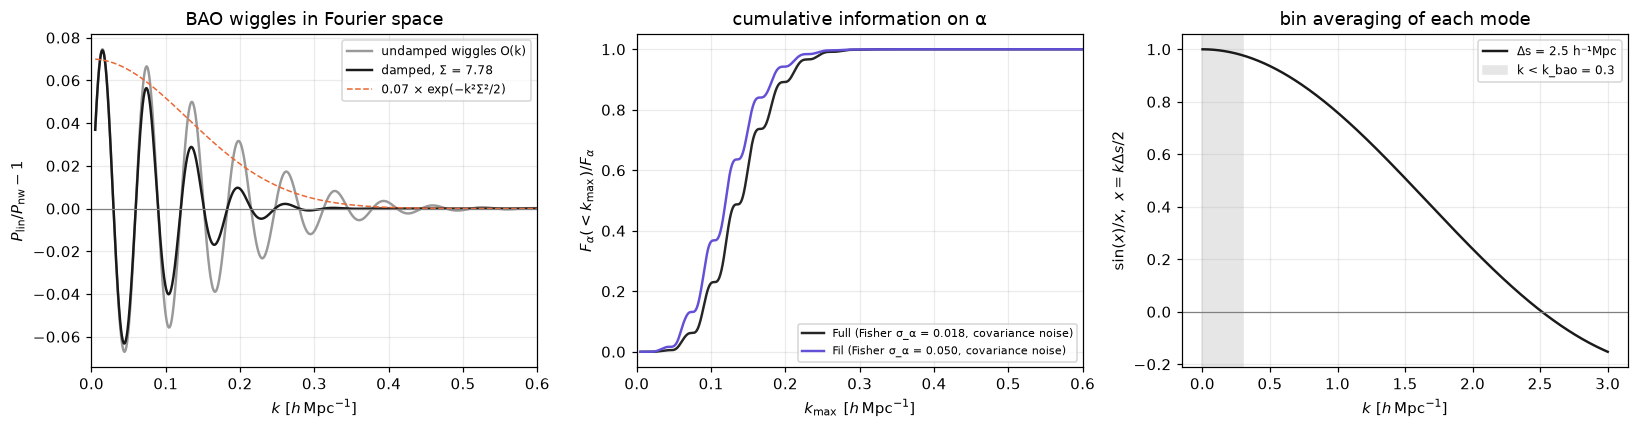

In [7]:
S_, rd_ = Sigma_th, lin['rd']
kf = np.linspace(0.005, 1.0, 4000)
Pl_, Pn_ = np.interp(kf, k, P_w), np.interp(kf, k, P_nw)
O_ = Pl_ / Pn_ - 1; D_ = np.exp(-kf**2 * S_**2 / 2)

def P_tot_cov(lab):
    # total power of one mode (signal + noise) on the grid kf: the spectrum the covariance uses,
    # bf.spectrum_for_cov with the sample's covariance bias (section 1b)
    i, b = spec['labels'].index(samples[lab]), data[lab]['b']
    return bf.spectrum_for_cov(spec, i, i, b, b, lin, kf)[0]

def fisher_alpha(b, Sigma, P_tot):
    # cumulative Fisher information on alpha, F_alpha(< k) on the grid kf: wiggles only, with amplitude b^2 and
    # damping exp(-k^2 Sigma^2 / 2); the error of one mode is P_tot (from P_tot_cov); volume L_BOX^3.
    # sigma_alpha^F = F_alpha(< kf[-1])^(-1/2).  Also used in section 5b.
    D = np.exp(-kf**2 * Sigma**2 / 2)
    dPda = -kf * np.gradient(O_, kf) * D * Pn_ * b**2
    return np.cumsum(kf**2 * (dPda / P_tot)**2) * (kf[1] - kf[0]) * bf.L_BOX**3 / (4 * np.pi**2)

fig, (a0, a1, a2) = plt.subplots(1, 3, figsize=(15, 4))
# numbers quoted in the text above
half = np.pi / rd_                                               # half a wiggle period
env = lambda y, kx: np.abs(y[(kf > kx - half) & (kf < kx + half)]).max()
print(f"r_d = {rd_:.2f} h^-1 Mpc, wiggle period 2 pi / r_d = {2 * np.pi / rd_:.4f} h/Mpc, Sigma_th = {S_:.2f}")
print(f"{'k':>6}{'D(k)':>10}{'|O| undamped':>14}{'|O| damped':>12}")
for kx in (0.1, 0.2, 0.3, 0.4, 0.6):
    print(f"{kx:>6}{np.exp(-kx**2 * S_**2 / 2):>10.2g}{env(O_, kx):>14.2g}{env(O_ * D_, kx):>12.2g}")
sg = np.arange(60., 140.01, 0.1)
def fwhm(S):
    y = sg**2 * T.xi_wig(S, s=sg); i0 = np.argmax(y); h = y[i0] / 2
    return sg[i0 + np.argmax(y[i0:] < h)] - sg[i0 - np.argmax(y[i0::-1] < h)]
print(f"FWHM of the BAO bump s^2 (xi - xi_nw): {fwhm(0.):.1f} h^-1 Mpc undamped, {fwhm(S_):.1f} with Sigma_th")
for ds in (binsep,):
    print(f"bin width {ds:g}: sin(x)/x = {np.sinc(k_bao * ds / 2 / np.pi):.2f} at k_bao = {k_bao}, "
          f"2/pi at k = pi/ds = {np.pi / ds:.2f}, 0 at k = 2 pi/ds = {2 * np.pi / ds:.2f}")
sig_fisher = {}

a0.plot(kf, O_, color='0.6', label='undamped wiggles O(k)')
a0.plot(kf, O_ * D_, color='0.1', label=f'damped, Σ = {S_:.2f}')
a0.plot(kf, 0.07 * D_, color='#eb6834', ls='--', lw=1, label='0.07 × exp(−k²Σ²/2)')
a0.axhline(0, color='0.5', lw=0.8); a0.set_xlim(0, 0.6); a0.set_xlabel(r'$k\ [h\,{\rm Mpc}^{-1}]$')
a0.set_ylabel(r'$P_{\rm lin}/P_{\rm nw}-1$'); a0.legend(fontsize=8); a0.set_title('BAO wiggles in Fourier space')
for lab in [l for l in ('Full', 'Fil') if l in data]:
    F = fisher_alpha(data[lab]['b'], S_, P_tot_cov(lab))
    sig_fisher[lab] = 1 / np.sqrt(F[-1])
    a1.plot(kf, F / F[-1], color=SCOL[lab], label=f'{lab} (Fisher σ_α = {sig_fisher[lab]:.3f}, covariance noise)')
    for km in (0.15, 0.2, 0.3):
        print(f"{lab}: fraction of the alpha information from k < {km}: {F[np.searchsorted(kf, km)] / F[-1]:.3f}")
a1.set_xlim(0, 0.6); a1.set_xlabel(r'$k_{\max}\ [h\,{\rm Mpc}^{-1}]$'); a1.set_ylabel(r'$F_\alpha(<k_{\max})/F_\alpha$')
a1.legend(fontsize=7); a1.set_title('cumulative information on α')
kb = np.linspace(1e-3, 3, 2000)
for ds, ls in ((binsep, '-'),):
    a2.plot(kb, np.sinc(kb * ds / 2 / np.pi), color='0.1', ls=ls, label=f'Δs = {ds:g} h⁻¹Mpc')
a2.axvspan(0, k_bao, color='0.9', zorder=0, label=f'k < k_bao = {k_bao}')
a2.axhline(0, color='0.5', lw=0.8); a2.set_xlabel(r'$k\ [h\,{\rm Mpc}^{-1}]$')
a2.set_ylabel(r'$\sin(x)/x,\ x = k\Delta s/2$'); a2.legend(fontsize=8); a2.set_title('bin averaging of each mode')
fig.tight_layout(); plt.show()

### Where Σ_th comes from

Σ is the typical distance by which two galaxies that started r_d apart have moved *relative to each other*
since early times. That relative motion smears the BAO peak. It is computed from linear theory with the
Zel'dovich approximation (ESW07 §4–5; Chen+24 eq. 9), in `bf.sigma_nl_theory`.

1. **Displacement field.** In the Zel'dovich approximation each galaxy moves by Ψ(q), with
   Ψ(k) = i k δ(k)/k² in Fourier space (the gradient of the linear potential). So the power spectrum of each
   Cartesian component is P_lin(k)/k² times the square of that component's direction cosine.
2. **One galaxy.** The variance of one component of the displacement of a single galaxy is
   σ₁² = (1/3) ∫ d³k/(2π)³ P_lin(k)/k² = (1/3) ∫ dk/(2π²) P_lin(k).
3. **Two galaxies a distance r apart.** Long waves (k ≪ 1/r) move both together and cancel in the
   difference; short waves move them independently. Averaged over directions, the variance per component of
   Ψ(x) − Ψ(x + r) is

   **Σ² = (2/3) ∫₀^∞ dk/(2π²) P_lin(k) [1 − j₀(k r)]**,  with j₀(x) = sin x / x and r = r_d.

   The factor 1 − j₀(k r_d) is ≈ 0 for k ≪ 1/r_d and → 1 for k ≫ 1/r_d. (Along and across the separation the
   two components differ by ± j₂ terms; their monopole average leaves only the j₀ term.)
4. **Numbers.** The cell evaluates this with the MultiDark-Planck P_lin at z = 0 and prints Σ_th, σ₈ and σ₁.
   Σ² is proportional to the amplitude of P_lin, so Σ scales linearly with σ₈. For r → ∞, j₀ → 0 and
   Σ → √2 σ₁: a single-galaxy estimate (σ₁) is too small by √2.

Left: the integrand per ln k, dΣ²/d ln k = (2/3) k P_lin(k) [1 − j₀(k r_d)]/(2π²), and the same without the
[1 − j₀] factor (dotted). Right: Σ accumulated up to k_max. The cell prints the fraction of Σ² from very
large scales (k < 0.02, which move both galaxies together), from 0.02 < k < k_bao (large-scale flows, where
linear theory is reliable) and from k > k_bao (where it is less so; one reason the α fit uses a Gaussian
prior of width `Sigma_prior_sd` around Σ_th rather than a fixed value).

r_d = 100.07 h^-1 Mpc,  sigma_8 = 0.8228
Sigma (pairwise, this cell) = 7.779   bf.sigma_nl_theory = 7.779 h^-1 Mpc
sigma_1 (one galaxy, per axis) = 5.961;  sqrt(2) sigma_1 = 8.430 (pairwise limit for r -> infinity)
  Sigma from k < 0.02: 1.81
  Sigma from k < 0.05: 4.63
  Sigma from k < 0.1 : 6.05
  Sigma from k < 0.2 : 6.94
  Sigma from k < 0.3 : 7.26
  Sigma from k < 0.5 : 7.51
fraction of Sigma^2 from k < 0.02: 0.05;  0.02 < k < k_bao = 0.3: 0.82;  k > k_bao: 0.13


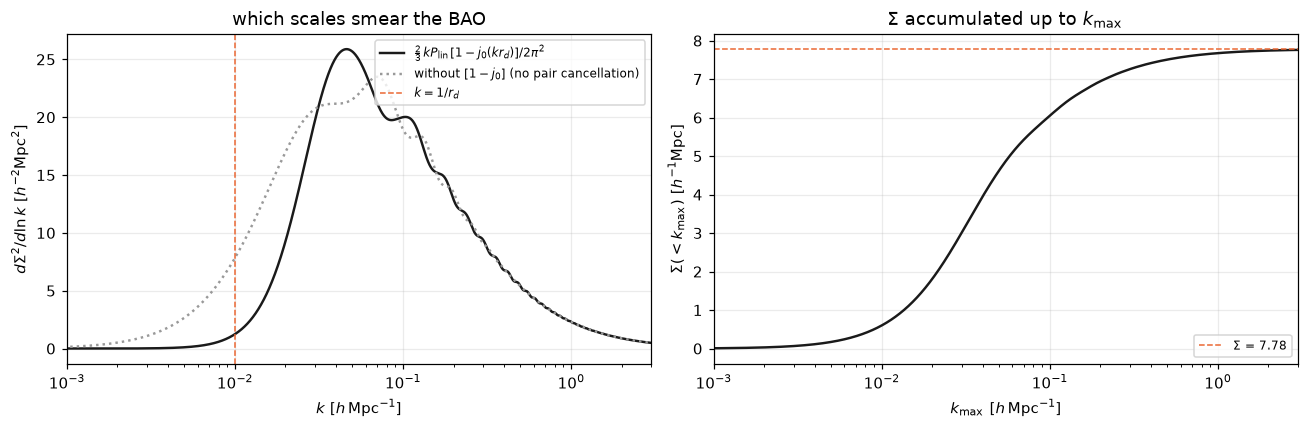

In [8]:
kh, Pk, rd = lin['kh'], lin['pk'], lin['rd']
j0 = np.sinc(kh * rd / np.pi)
dS2_dlnk = (2. / 3.) * kh * Pk * (1. - j0) / (2 * np.pi**2)          # integrand per ln k
dS2_dlnk_one = (2. / 3.) * kh * Pk / (2 * np.pi**2)                    # same without the pair factor
lnk = np.log(kh)
S2_cum = np.concatenate([[0.], np.cumsum(0.5 * (dS2_dlnk[1:] + dS2_dlnk[:-1]) * np.diff(lnk))])
Sigma_calc = np.sqrt(S2_cum[-1])
sigma1 = np.sqrt(np.trapezoid(Pk, kh) / (3 * 2 * np.pi**2))
print(f"r_d = {rd:.2f} h^-1 Mpc,  sigma_8 = {lin['sigma8']:.4f}")
print(f"Sigma (pairwise, this cell) = {Sigma_calc:.3f}   bf.sigma_nl_theory = {Sigma_th:.3f} h^-1 Mpc")
print(f"sigma_1 (one galaxy, per axis) = {sigma1:.3f};  sqrt(2) sigma_1 = {np.sqrt(2) * sigma1:.3f} (pairwise limit for r -> infinity)")
for km in (0.02, 0.05, 0.1, 0.2, 0.3, 0.5):
    print(f"  Sigma from k < {km:<4}: {np.sqrt(np.interp(np.log(km), lnk, S2_cum)):.2f}")
fS2 = lambda km: np.interp(np.log(km), lnk, S2_cum) / S2_cum[-1]
print(f"fraction of Sigma^2 from k < 0.02: {fS2(0.02):.2f};  0.02 < k < k_bao = {k_bao}: "
      f"{fS2(k_bao) - fS2(0.02):.2f};  k > k_bao: {1 - fS2(k_bao):.2f}")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
a1.semilogx(kh, dS2_dlnk, color='0.1', label=r'$\frac{2}{3}\,k P_{\rm lin}\,[1-j_0(k r_d)]/2\pi^2$')
a1.semilogx(kh, dS2_dlnk_one, color='0.6', ls=':', label='without $[1-j_0]$ (no pair cancellation)')
a1.axvline(1 / rd, color='#eb6834', ls='--', lw=1, label=r'$k = 1/r_d$')
a1.set_xlim(1e-3, 3); a1.set_xlabel(r'$k\ [h\,{\rm Mpc}^{-1}]$'); a1.set_ylabel(r'$d\Sigma^2/d\ln k\ [h^{-2}{\rm Mpc}^2]$')
a1.legend(fontsize=8); a1.set_title('which scales smear the BAO')
a2.semilogx(kh, np.sqrt(S2_cum), color='0.1')
a2.axhline(Sigma_th, color='#eb6834', ls='--', lw=1, label=f'Σ = {Sigma_th:.2f}')
a2.set_xlim(1e-3, 3); a2.set_xlabel(r'$k_{\max}\ [h\,{\rm Mpc}^{-1}]$'); a2.set_ylabel(r'$\Sigma(<k_{\max})\ [h^{-1}{\rm Mpc}]$')
a2.legend(fontsize=8); a2.set_title('Σ accumulated up to $k_{\\max}$')
fig.tight_layout(); plt.show()

## 2. The fits

desilike settings as in `desilike_test_full.ipynb` and `desilike_run1.ipynb`: real space (`dbeta` = 0,
`sigmas` = 0), isotropic damping (`sigmapar` = `sigmaper` = Σ), broadband a₀ + a₁/s + a₂/s², Wallisch
no-wiggle (`with_now='wallish2018'`), model averaged over each data bin (`wmatrix={'resolution': 10}`),
Minuit. Takes a few minutes (each fit recomputes its template).

The χ² of the α fit includes the Σ prior term ((Σ − Σ_th)/`Sigma_prior_sd`)², which desilike keeps in the
log-prior, not in the likelihood. Degrees of freedom: dof = N_bins + 1 − N_par, where N_bins is the number
of bins in the fit range, the Gaussian Σ prior counts as one data point, and N_par is the number of
parameters varied by desilike in the α fit (printed by the cell).

The Σ fit is run with the α interval switched on (`interval=True`), so it gives "α, Σ free": α and its
Δχ² = 1 interval with Σ profiled over the flat prior `Sigma_free`. Its χ² has no prior term (the flat
prior is constant), and its dof = N_bins − N_par.

**Σ interval and Δχ²(Σ_th).** For the Σ fit the cell also computes the profile

$$
\chi^2_{\rm prof}(\Sigma)=\min_{\alpha,\,b_1,\,a_{-2},\,a_{-1},\,a_0}\chi^2(\Sigma,\alpha,b_1,a_{-2},a_{-1},a_0),
\qquad
\boxed{\;\Delta\chi^2(\Sigma)=\chi^2_{\rm prof}(\Sigma)-\chi^2_{\rm min}\;}
$$

At each Σ of a grid over `Sigma_free` (step `Sigma_step`, plus Σ_th and the best-fit Σ) desilike refits all
the other varied parameters: α (`qiso`), the amplitude $b_1$ (`b1`) and the broadband coefficients
$a_{-2},a_{-1},a_0$ (`al0_-2`, `al0_-1`, `al0_0`). χ²_min is the smallest χ²_prof on the grid. Same rule as
for α: the 68% interval of Σ is where Δχ²(Σ) ≤ 1, with the crossings interpolated linearly between grid
points. Σ cannot be negative, so if Δχ² stays below 1 down to Σ = 0 the interval reaches the edge of
`Sigma_free` and only its upper end is a bound. **Δχ²(Σ_th)** is Δχ²(Σ) at the Zel'dovich prediction Σ_th:
≲ 1 means the data are consistent with the predicted damping, several units means they prefer a different Σ.
The grid adds a few dozen fits per sample, so this cell is slower.

In [9]:
def desilike_theory(prior='gauss', only_now=False):
    # the BAO model of all fits (one sample); returns the theory and its template
    tpl = BAOPowerSpectrumTemplate(z=0., fiducial=cosmo, apmode='qiso', with_now='wallish2018', only_now=only_now)
    th = DampedBAOWigglesTracerCorrelationFunctionMultipoles(ells=(0,), template=tpl, broadband='power')
    P = th.init.params
    P['dbeta'].update(value=0., fixed=True)
    P['sigmas'].update(value=0., fixed=True)
    if prior == 'gauss':
        P['sigmaper'].update(fixed=False, value=Sigma_th, prior=dict(dist='norm', loc=Sigma_th, scale=Sigma_prior_sd, limits=[0., 30.]))
    else:
        P['sigmaper'].update(fixed=False, value=Sigma_th, prior=dict(limits=list(Sigma_free)))
    P['sigmapar'].update(derived='{sigmaper}')
    for name in ('al0_1', 'al0_2'):
        P[name].update(value=0., fixed=True)
    if only_now:
        P['sigmaper'].update(fixed=True, value=Sigma_th, prior=None)
        tpl.init.params['qiso'].update(fixed=True, value=1.)
    return th, tpl

def desilike_lik(d, prior='gauss', only_now=False):
    th, _ = desilike_theory(prior, only_now)
    m = d['m']
    obs = TracerCorrelationFunctionMultipolesObservable(
        data=d['xi'][m], s=d['s'][m], covariance=d['C'][np.ix_(m, m)],
        slim={0: (fit_range[0], fit_range[1], binsep)}, wmatrix={'resolution': 10}, theory=th)
    return ObservablesGaussianLikelihood(observables=[obs]), obs

def desilike_fit(lik, interval=False):
    prof = MinuitProfiler(lik, seed=42)
    prof.maximize(niterations=5)
    b = prof.profiles.bestfit
    i = int(np.argmax(b.logposterior))
    pars = {p.name: float(b[p.name][i]) for p in lik.varied_params}
    out = dict(prof=prof, pars=pars, chi2=-2 * float(b['loglikelihood'][i]))
    if interval:
        prof.interval(params=['qiso'])
        iv = prof.profiles.interval['qiso']
        lo, hi = pars['qiso'] + iv[0], pars['qiso'] + iv[1]
        # desilike stops the interval at the prior edges (0.8, 1.2): report that as open
        out['lo'] = np.nan if lo <= 0.8 + 1e-3 else lo
        out['hi'] = np.nan if hi >= 1.2 - 1e-3 else hi
    return out

def interval_68(x, dchi2):
    # Delta chi2 = 1 interval around the minimum of a profile, crossings interpolated linearly between
    # grid points; nan on a side where Delta chi2 stays below 1 up to the end of the grid
    i0 = int(np.argmin(dchi2))
    up = [i for i in range(i0, len(x)) if dchi2[i] > 1]
    dn = [i for i in range(i0, -1, -1) if dchi2[i] > 1]
    hi = np.interp(1., dchi2[[up[0] - 1, up[0]]], x[[up[0] - 1, up[0]]]) if up else np.nan
    lo = np.interp(1., dchi2[[dn[0] + 1, dn[0]]], x[[dn[0] + 1, dn[0]]]) if dn else np.nan
    return lo, hi

def sigma_profile(lik, Sigma_best):
    # Delta chi2(Sigma) = chi2_prof(Sigma) - chi2_min on a grid over Sigma_free (all other varied parameters
    # refitted at each point), its Delta chi2 = 1 interval and its value at Sigma_th.  lo / hi = nan: the
    # interval reaches the edge of Sigma_free on that side.
    grid = np.union1d(np.arange(Sigma_free[0], Sigma_free[1] + 1e-9, Sigma_step), [Sigma_th, Sigma_best])
    prof = MinuitProfiler(lik, seed=42)
    prof.profile(params=['sigmaper'], grid=grid)
    pr = np.asarray(prof.profiles.profile['sigmaper'])
    S, dchi2 = pr[:, 0], -2 * (pr[:, 1] - pr[:, 1].max())     # flat prior: log-posterior = log-likelihood + const
    lo, hi = interval_68(S, dchi2)
    return dict(S=S, dchi2=dchi2, lo=lo, hi=hi, dchi2_th=float(dchi2[np.argmin(np.abs(S - Sigma_th))]))

res = {}
t0 = time.time()
for lab, d in data.items():
    lik_a, obs_a = desilike_lik(d, 'gauss'); f_a = desilike_fit(lik_a, interval=True)
    lik_S, obs_S = desilike_lik(d, 'flat');  f_S = desilike_fit(lik_S, interval=True)
    lik_n, _ = desilike_lik(d, only_now=True); f_n = desilike_fit(lik_n)
    lik_a(**f_a['pars']); model = np.array(obs_a.flattheory)
    lik_S(**f_S['pars']); model_S = np.array(obs_S.flattheory)
    chi2 = f_a['chi2'] + ((f_a['pars']['sigmaper'] - Sigma_th) / Sigma_prior_sd)**2
    n_par = len(lik_a.varied_params)
    prof_Sig = sigma_profile(lik_S, f_S['pars']['sigmaper'])
    res[lab] = dict(fit=f_a, fit_S=f_S, fit_nw=f_n, lik_a=lik_a, lik_S=lik_S, model=model, model_S=model_S,
                    chi2=chi2, det=f_n['chi2'] - chi2, dof=int(d['m'].sum()) + 1 - n_par, prof_Sig=prof_Sig,
                    dof_S=int(d['m'].sum()) - len(lik_S.varied_params))
    print(f"{lab:<18} alpha = {f_a['pars']['qiso']:.4f}   alpha (Sigma free) = {f_S['pars']['qiso']:.4f} "
          f"at Sigma = {f_S['pars']['sigmaper']:.2f}   dchi2(Sigma_th) = {prof_Sig['dchi2_th']:.2f}   "
          f"({time.time() - t0:.0f} s)")
print(f"parameters varied in the alpha fit (N_par = {n_par}): {[p.name for p in lik_a.varied_params]}")

Full               alpha = 0.9760   alpha (Sigma free) = 0.9755 at Sigma = 6.10   dchi2(Sigma_th) = 0.24   (15 s)
Fil                alpha = 0.9743   alpha (Sigma free) = 0.9707 at Sigma = 0.00   dchi2(Sigma_th) = 1.26   (29 s)
NonFil             alpha = 0.9513   alpha (Sigma free) = 0.9490 at Sigma = 6.92   dchi2(Sigma_th) = 0.01   (45 s)
Full dil nFil      alpha = 0.9831   alpha (Sigma free) = 0.9874 at Sigma = 10.56   dchi2(Sigma_th) = 0.27   (60 s)
Full dil nNonFil   alpha = 0.9772   alpha (Sigma free) = 0.9757 at Sigma = 5.45   dchi2(Sigma_th) = 0.21   (75 s)
parameters varied in the alpha fit (N_par = 6): ['qiso', 'b1', 'sigmaper', 'al0_-2', 'al0_-1', 'al0_0']


## 3. Best fits

Data with errors, the best α-fit model (solid) and the best Σ-free model (dashed), and normalised residuals
(ξ − model)/σ (filled: α fit; open: Σ free).
The bins are correlated, so runs of same-sign residuals are expected and are not by themselves a sign of a
bad fit; the χ² in section 5 accounts for the correlations.

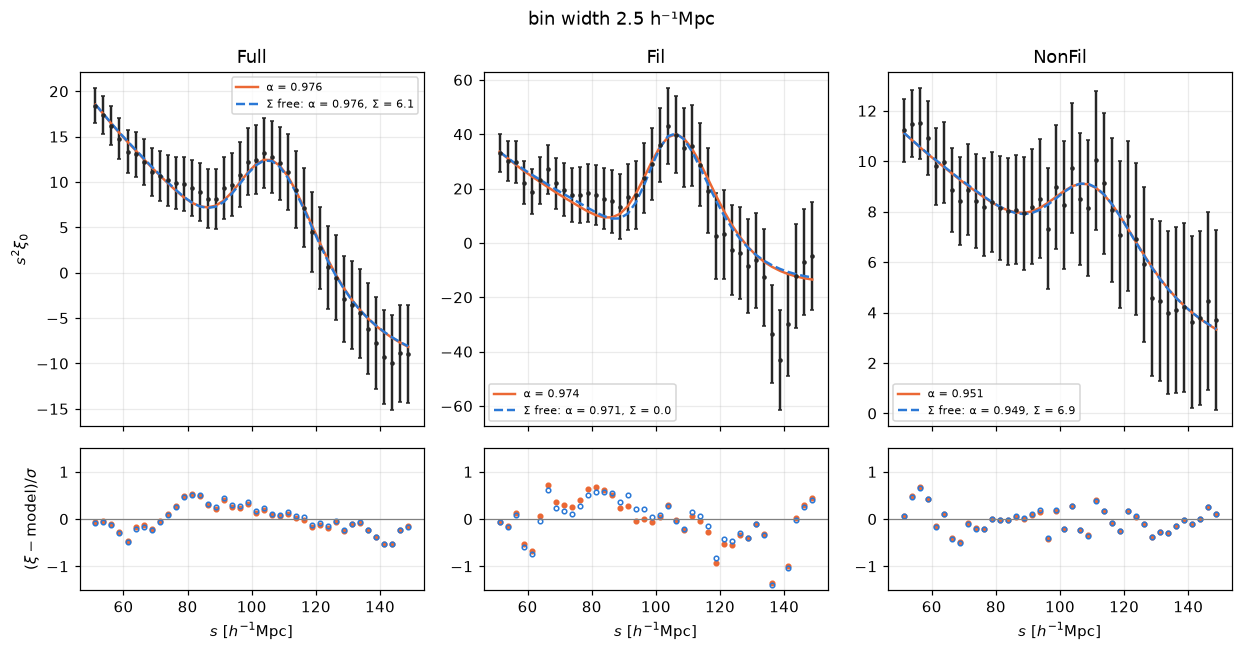

In [10]:
fig, axes = plt.subplots(2, len(labs_p), figsize=(3.8 * len(labs_p), 6), sharex=True,
                         gridspec_kw=dict(height_ratios=(2.5, 1)), squeeze=False)
for j, lab in enumerate(labs_p):
    d, r = data[lab], res[lab]; s, m, sg = d['s'], d['m'], d['sig']
    axes[0, j].errorbar(s[m], s[m]**2 * d['xi'][m], yerr=s[m]**2 * sg[m], fmt='.', ms=4, capsize=1.5, color=DATA)
    axes[0, j].plot(s[m], s[m]**2 * r['model'], color=DESI, label=f"α = {r['fit']['pars']['qiso']:.3f}")
    axes[0, j].plot(s[m], s[m]**2 * r['model_S'], color=FREE, ls='--',
                    label=f"Σ free: α = {r['fit_S']['pars']['qiso']:.3f}, Σ = {r['fit_S']['pars']['sigmaper']:.1f}")
    axes[1, j].plot(s[m], (d['xi'][m] - r['model']) / sg[m], 'o', ms=3, color=DESI)
    axes[1, j].plot(s[m], (d['xi'][m] - r['model_S']) / sg[m], 'o', ms=3, mfc='none', color=FREE)
    axes[1, j].axhline(0, color='0.5', lw=0.8); axes[1, j].set_xlabel(r'$s\ [h^{-1}{\rm Mpc}]$')
    axes[0, j].set_title(lab); axes[0, j].legend(fontsize=7)
    axes[1, j].set_ylim([-1.5, 1.5])
axes[0, 0].set_ylabel(r'$s^2\xi_0$'); axes[1, 0].set_ylabel(r'$(\xi-{\rm model})/\sigma$')
fig.suptitle(f'bin width {binsep:g} h⁻¹Mpc')
fig.tight_layout(); plt.show()

## 4. χ²(α) profiles

At each α on the grid, desilike refits all the other parameters; Δχ² is relative to the curve's minimum.
Solid: α fit (Gaussian Σ prior; the prior term is included). Dashed: Σ free (flat prior `Sigma_free`).
Dotted line: Δχ² = 1 (its crossings give the 68% interval of the table). A curve that stays below Δχ² = 1
over the whole α range means α is not constrained for that sample.

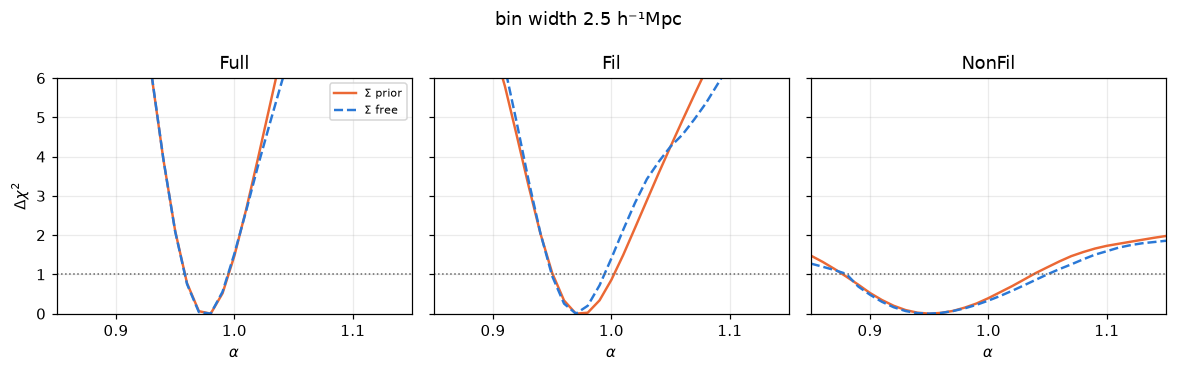

In [11]:
grid = np.linspace(0.85, 1.15, 31)
fig, axes = plt.subplots(1, len(labs_p), figsize=(3.6 * len(labs_p), 3.4), sharey=True, squeeze=False)
for j, lab in enumerate(labs_p):
    ax = axes[0, j]
    prof = MinuitProfiler(res[lab]['lik_a'], seed=42)
    prof.profile(params=['qiso'], grid=grid)
    pr = np.asarray(prof.profiles.profile['qiso'])
    ax.plot(pr[:, 0], -2 * (pr[:, 1] - pr[:, 1].max()), color=DESI, label='Σ prior')
    prof_S = MinuitProfiler(res[lab]['lik_S'], seed=42)
    prof_S.profile(params=['qiso'], grid=grid)
    pr_S = np.asarray(prof_S.profiles.profile['qiso'])
    ax.plot(pr_S[:, 0], -2 * (pr_S[:, 1] - pr_S[:, 1].max()), color=FREE, ls='--', label='Σ free')
    ax.axhline(1, color='0.4', ls=':', lw=1); ax.set_xlim(grid[0], grid[-1]); ax.set_ylim(0, 6)
    ax.set_xticks([0.9, 1.0, 1.1])
    ax.set_title(lab); ax.set_xlabel(r'$\alpha$')
axes[0, 0].set_ylabel(r'$\Delta\chi^2$'); axes[0, 0].legend(fontsize=7)
fig.suptitle(f'bin width {binsep:g} h⁻¹Mpc'); fig.tight_layout(); plt.show()

## 5. Summary table

* α [68%]: α fit, profile best fit and Δχ² = 1 interval (`open` if it reaches the edge of the α prior,
  0.8–1.2).
* α, Σ free [68%]: the same, from the Σ fit (flat Σ prior `Sigma_free`).
* Σ [68%]: Σ fit (flat prior), profile best fit and Δχ² = 1 interval from χ²_prof(Σ) (section 2); `edge` if
  the interval reaches the edge of `Sigma_free` (at Σ = 0: only the upper end is a bound).
* Δχ²(Σ_th): Δχ²(Σ) = χ²_prof(Σ) − χ²_min at Σ = Σ_th (section 2).
* χ²/dof (Σ free): χ² of the Σ fit, dof = N_bins − N_par.
* χ²/dof of the α fit, prior term included (section 2).
* Δχ²_det = χ²(no-wiggle) − χ²(α fit).

Below the table: σ_α^Fisher (section 1c, wiggles only) next to the half-width of the α interval.

In [12]:
def fmt_a(a, lo, hi):
    f = lambda x: 'open' if not np.isfinite(x) else f'{x:.3f}'
    return f"{a:.4f} [{f(lo)}, {f(hi)}]"

def fmt_S(S, lo, hi):
    f = lambda x: 'edge' if not np.isfinite(x) else f'{x:.2f}'
    return f"{S:.2f} [{f(lo)}, {f(hi)}]"

hdr = (f"{'sample':<18}| {'alpha [68%]':<25}| {'alpha, Sigma free [68%]':<25}| {'Sigma [68%]':<21}| {'dchi2(Sig_th)':>13} | "
       f"{'chi2/dof':<11}| {'chi2/dof Sfree':<14}| {'dchi2_det':>9}")
print(f"bin width {binsep:g} h^-1 Mpc, magnitude cut {mag}"); print(hdr); print('-' * len(hdr))
for lab in labs:
    r = res[lab]; f, fS, pS = r['fit'], r['fit_S'], r['prof_Sig']
    print(f"{lab:<18}| {fmt_a(f['pars']['qiso'], f['lo'], f['hi']):<25}| "
          f"{fmt_a(fS['pars']['qiso'], fS['lo'], fS['hi']):<25}| {fmt_S(fS['pars']['sigmaper'], pS['lo'], pS['hi']):<21}| "
          f"{pS['dchi2_th']:>13.2f} | "
          f"{r['chi2']:>5.1f}/{r['dof']:<5d}| {fS['chi2']:>5.1f}/{r['dof_S']:<8d}| {r['det']:>9.2f}")

print()
for lab, sf in sig_fisher.items():
    f = res[lab]['fit']
    hw = 0.5 * (f['hi'] - f['lo'])
    print(f"{lab}: Fisher sigma_alpha = {sf:.3f} (wiggles only, covariance noise);  fit half-width = "
          + ('open' if not np.isfinite(hw) else f"{hw:.3f}"))

bin width 2.5 h^-1 Mpc, magnitude cut -20.8
sample            | alpha [68%]              | alpha, Sigma free [68%]  | Sigma [68%]          | dchi2(Sig_th) | chi2/dof   | chi2/dof Sfree| dchi2_det
-------------------------------------------------------------------------------------------------------------------------------------------------------
Full              | 0.9760 [0.958, 0.995]    | 0.9755 [0.958, 0.994]    | 6.10 [2.66, 9.80]    |          0.24 |  22.7/35   |  22.6/34      |     15.30
Fil               | 0.9743 [0.951, 1.002]    | 0.9707 [0.950, 0.992]    | 0.00 [edge, 6.97]    |          1.26 |  31.2/35   |  30.5/34      |      8.53
NonFil            | 0.9513 [0.877, 1.038]    | 0.9490 [0.877, 1.050]    | 6.92 [edge, edge]    |          0.01 |  23.8/35   |  23.8/34      |      1.64
Full dil nFil     | 0.9831 [0.955, 1.014]    | 0.9874 [0.957, 1.021]    | 10.56 [4.08, 15.39]  |          0.27 |  20.9/35   |  20.8/34      |      8.93
Full dil nNonFil  | 0.9772 [0.958, 1.000]   

## 5b. Expected error on α: Fisher forecast per sample

**Why.** The α intervals of section 5 come from one realization: the width of a profile depends on the data
themselves (e.g. it shrinks when the fitted Σ runs to 0). The Fisher forecast gives the error expected *on
average* for a sample with a given volume, spectrum and damping, and it separates the effect of each.

**What it computes.** The integral of section 1c (function `fisher_alpha`), for each sample:

$$
F_\alpha=\frac{V}{4\pi^2}\int_0^{k_{\max}}k^2\,dk\left[\frac{\partial P_g/\partial\alpha}{P_{\rm tot}(k)}\right]^2,
\qquad
\boxed{\;\sigma_\alpha^F=F_\alpha^{-1/2}\;}
$$

where $V=L^3$ is the box volume, $V k^2dk/(4\pi^2)$ the number of independent Fourier modes in a shell of width
$dk$, $k_{\max}$ the end of the grid `kf` of section 1c, and

* $P_g(k)=b^2P_{\rm nw}(k)\,[1+O(k/\alpha)\,D(k)]$ the galaxy power spectrum: $b$ the bias (the covariance bias of
  section 1), $P_{\rm nw}$ the no-wiggle spectrum, $O(k)=P_{\rm lin}/P_{\rm nw}-1$ the wiggles, $D(k)=e^{-k^2\Sigma^2/2}$ the damping;
* $\partial P_g/\partial\alpha\,|_{\alpha=1}=-b^2\,k\,O'(k)\,D(k)\,P_{\rm nw}(k)$: only the wiggles move with α;
* $P_{\rm tot}(k)$ the error of one mode: the total power, signal plus noise, **the same spectrum the covariance uses**
  (`P_tot_cov`, i.e. `bf.spectrum_for_cov`: $b^2P_{\rm lin}+N$ below k_lo, the measured spectrum above; section 1b).

Dividing numerator and denominator by $b^2P_{\rm nw}$, the information per mode is

$$
\boxed{\;\left[\frac{\partial P_g/\partial\alpha}{P_{\rm tot}}\right]^2=
\left[\frac{k\,O'(k)\,D(k)}{R(k)}\right]^2,\qquad R(k)=\frac{P_{\rm tot}(k)}{b^2P_{\rm nw}(k)}\;}
$$

so a sample enters only through Σ (in $D$) and through $R$, the error of a mode in units of the smooth signal
power. $R\simeq1$: the mode is limited by cosmic variance; $R\gg1$: by noise. With Poisson noise only, $R\simeq1+1/(\bar n\,b^2P_{\rm nw})$
($\bar n=N/V$); the measured $R$ is larger by the excess power of section 1b (non-linear clustering and
non-Poisson noise), which acts as noise for the BAO.

**What the cell shows.**
* **(a)** For each sample: b, n̄, $R$ at `k_R` (with the covariance spectrum, and with Poisson noise only), the fitted Σ
  and its 68% interval (Σ fit, section 2), $\sigma_\alpha^F$ at Σ_th, at the fitted Σ and over the Σ interval ($\sigma_\alpha^F$ grows
  with Σ), next to the measured half-widths (hi − lo)/2 of the α intervals of the α fit and of the α, Σ-free fit.
  An open side of the Σ interval is replaced by the end of `Sigma_free`.
* **(b)** Each subsample A against its random dilution (same N): the 2×2 table of $\sigma_\alpha^F$ with the spectrum
  ($b$ and $P_{\rm tot}$ together, i.e. $R$) and the fitted Σ taken from A or from the dilution. The ratios give the change
  of $\sigma_\alpha^F$ from the spectrum alone (at the dilution's Σ), from Σ alone (with the dilution's spectrum), and from
  both, next to the measured ratio of the half-widths. If the two effects were independent, the product of the first
  two ratios would equal the third.
* **(c)** $\sigma_\alpha^F$ as a function of Σ for every sample (the dilutions are drawn here, dashed, because they are
  the reference), the fitted Σ with its 68% interval (filled marker), and the measured α, Σ-free half-width at the
  fitted Σ (open marker).

**How to read it.** $\sigma_\alpha^F$ is a lower bound for the fits: it counts the wiggles only, with Σ and the broadband
fixed. Compare samples through ratios rather than absolute values, and keep in mind that the fitted Σ and the bias
are themselves uncertain (the bars in (c); the bias warning of section 1).

bin width 2.5 h^-1 Mpc, magnitude cut -20.8, Sigma_th = 7.78;  sigma^F: wiggles only, error of a mode = covariance spectrum, V = L^3;  R at k = 0.15 h/Mpc
sample            |     b | n [h^3 Mpc^-3] | R cov | R Poisson | Sigma fit [68%]    | sF(Sig_th) | sF(Sig_fit) | sF over Sigma [68%]| s_alpha fit | s_alpha Sfree
-----------------------------------------------------------------------------------------------------------------------------------------------------------------
Full              | 0.978 |       5.00e-03 |  1.14 |      1.07 |  6.10 [ 2.66,  9.80] |     0.0179 |      0.0135 | [0.0080, 0.0249]  |       0.018 |         0.018
Fil               | 1.384 |       1.04e-03 |  3.56 |      1.16 |  0.00 [ 0.00,  6.97] |     0.0503 |      0.0236 | [0.0236, 0.0452]  |       0.026 |         0.021
NonFil            | 0.722 |       2.18e-03 |  2.32 |      1.28 |  6.92 [ 0.00, 16.00] |     0.0306 |      0.0274 | [0.0141, 0.0780]  |       0.081 |         0.087
Full dil nFil     | 0.961 |     

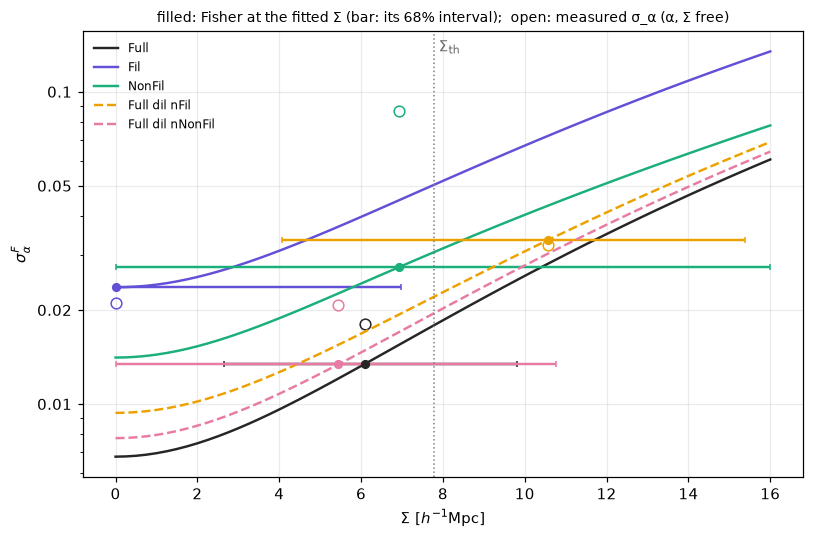

In [13]:
# Fisher sigma_alpha (fisher_alpha, section 1c) at each sample's own b, covariance spectrum P_tot and Sigma
import matplotlib.ticker as mticker
k_R = 0.15                          # [h/Mpc] where R = P_tot / (b^2 P_nw) is printed (middle of the BAO information, 1c)
P_tot = {lab: P_tot_cov(lab) for lab in labs}
sig_F = lambda b, S, Pt: 1 / np.sqrt(fisher_alpha(b, S, Pt)[-1])
nbar_of = lambda lab: data[lab]['n_gal'] / bf.L_BOX**3
half_width = lambda f: 0.5 * (f['hi'] - f['lo'])          # of a 68% interval; nan if open on a side
S_fit = {lab: res[lab]['fit_S']['pars']['sigmaper'] for lab in labs}
# 68% interval of Sigma (section 2); an open side ('edge' in the table) is replaced by the end of Sigma_free
S_int = {lab: (np.nan_to_num(res[lab]['prof_Sig']['lo'], nan=Sigma_free[0]),
               np.nan_to_num(res[lab]['prof_Sig']['hi'], nan=Sigma_free[1])) for lab in labs}
fmt = lambda x: '  open' if not np.isfinite(x) else f'{x:6.3f}'
jR = np.searchsorted(kf, k_R)

# (a) Fisher forecast next to the measured errors.  R at k_R: with the covariance spectrum, and with Poisson noise
#     only (1 + 1/(n b^2 P_nw)); the difference is the excess power of section 1b.  sigma_alpha^F grows with Sigma,
#     so the Sigma interval maps onto [sigma^F(Sigma_lo), sigma^F(Sigma_hi)].
print(f"bin width {binsep:g} h^-1 Mpc, magnitude cut {mag}, Sigma_th = {Sigma_th:.2f};  sigma^F: wiggles only, "
      f"error of a mode = covariance spectrum, V = L^3;  R at k = {k_R:g} h/Mpc")
hdr = (f"{'sample':<18}| {'b':>5} | {'n [h^3 Mpc^-3]':>14} | {'R cov':>5} | {'R Poisson':>9} | {'Sigma fit [68%]':<19}| "
       f"{'sF(Sig_th)':>10} | {'sF(Sig_fit)':>11} | {'sF over Sigma [68%]':<19}| {'s_alpha fit':>11} | {'s_alpha Sfree':>13}")
print(hdr); print('-' * len(hdr))
for lab in labs:
    b, n, Pt, (lo, hi) = data[lab]['b'], nbar_of(lab), P_tot[lab], S_int[lab]
    R, R_P = Pt[jR] / (b**2 * Pn_[jR]), 1 + 1 / (n * b**2 * Pn_[jR])
    print(f"{lab:<18}| {b:5.3f} | {n:14.2e} | {R:5.2f} | {R_P:9.2f} | {S_fit[lab]:5.2f} [{lo:5.2f}, {hi:5.2f}] | "
          f"{sig_F(b, Sigma_th, Pt):10.4f} | {sig_F(b, S_fit[lab], Pt):11.4f} | "
          f"[{sig_F(b, lo, Pt):.4f}, {sig_F(b, hi, Pt):.4f}]  | "
          f"{fmt(half_width(res[lab]['fit'])):>11} | {fmt(half_width(res[lab]['fit_S'])):>13}")

# (b) each subsample against its random dilution (same N): sigma^F with the spectrum (b and P_tot together, i.e. R)
#     and the fitted Sigma taken from one sample or the other
for A in dilution_of:
    B = f'Full dil n{A}'
    if A not in data or B not in data: continue
    assert data[A]['n_gal'] == data[B]['n_gal'], f"{A}, {B}: different N"
    SA, SB = S_fit[A], S_fit[B]
    t = {(i, j): sig_F(data[X]['b'], Sj, P_tot[X]) for i, X in (('A', A), ('B', B)) for j, Sj in (('A', SA), ('B', SB))}
    print(f"\n{A} vs {B} (N = {data[A]['n_gal']}): sigma_alpha^F with the spectrum (rows) and the fitted Sigma "
          f"(columns) of each sample")
    print(f"{'':<22}{'Sigma_' + A + f' = {SA:.2f}':>22}{'Sigma_dil' + f' = {SB:.2f}':>22}")
    for i, lab_i in (('A', A), ('B', 'dil')):
        print(f"{'spectrum of ' + lab_i:<22}{t[(i, 'A')]:>22.4f}{t[(i, 'B')]:>22.4f}")
    r_tot, r_P, r_S = t[('A', 'A')] / t[('B', 'B')], t[('A', 'B')] / t[('B', 'B')], t[('B', 'A')] / t[('B', 'B')]
    print(f"sigma^F({A}) / sigma^F(dil) = {r_tot:.3f};  spectrum alone (Sigma_dil): {r_P:.3f};  "
          f"Sigma alone (spectrum of dil): {r_S:.3f};  product of the two: {r_P * r_S:.3f}")
    print(f"measured ratio (alpha fit, Sigma prior): {half_width(res[A]['fit']) / half_width(res[B]['fit']):.3f};  "
          f"(alpha, Sigma free): {half_width(res[A]['fit_S']) / half_width(res[B]['fit_S']):.3f}")

# (c) sigma_alpha^F as a function of Sigma for each sample; marker = fitted Sigma with its 68% interval,
#     open marker = measured half-width of the (alpha, Sigma free) interval at the fitted Sigma
Sg = np.linspace(Sigma_free[0], Sigma_free[1], 65)
fig, ax = plt.subplots(figsize=(7.5, 5))
for lab in labs:
    b, Pt, c = data[lab]['b'], P_tot[lab], SCOL[lab]
    ax.plot(Sg, [sig_F(b, S, Pt) for S in Sg], color=c, ls='--' if lab.startswith('Full dil') else '-', label=lab)
    s0, (lo, hi) = S_fit[lab], S_int[lab]
    ax.errorbar(s0, sig_F(b, s0, Pt), xerr=[[s0 - lo], [hi - s0]], fmt='o', ms=5, color=c, capsize=2)
    hw = half_width(res[lab]['fit_S'])
    if np.isfinite(hw):
        ax.plot(s0, hw, 'o', ms=7, mfc='none', mec=c)
ax.axvline(Sigma_th, color='0.5', ls=':', lw=1)
ax.text(Sigma_th, 0.98, r' $\Sigma_{\rm th}$', transform=ax.get_xaxis_transform(), va='top', color='0.4')
ax.set_yscale('log'); ax.yaxis.set_major_locator(mticker.LogLocator(subs=(1, 2, 5)))
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'{v:g}'))
ax.yaxis.set_minor_formatter(mticker.NullFormatter())
ax.set_xlabel(r'$\Sigma\ [h^{-1}{\rm Mpc}]$'); ax.set_ylabel(r'$\sigma_\alpha^F$')
ax.legend(frameon=False, fontsize=8)
ax.set_title('filled: Fisher at the fitted Σ (bar: its 68% interval);  open: measured σ_α (α, Σ free)', fontsize=9)
fig.tight_layout(); plt.show()

## 6. The summary table as a figure

One panel per column of the section 5 table, for all samples; each random dilution sits next to the sample
whose N it matches (grey label). Filled orange: α fit
(Gaussian Σ prior); open blue: Σ fit (flat prior `Sigma_free`), shifted right.

* **α [68%]**, both fits; grey line α = 1. A side of an interval that is `open` in the table (it reaches the
  α prior edge) is dotted up to the edge of the panel.
* **Σ [68%]** from the Σ fit; dashed: Σ_th. A side marked `edge` in the table is dotted up to that edge of
  `Sigma_free`.
* **Δχ²(Σ_th)**; dotted: Δχ² = 1 (above it, Σ_th lies outside the 68% interval of Σ).
* **χ²_min/dof** of both fits; grey band: 1 ± √(2/dof), the expected scatter of χ²/dof if model and covariance
  are right (dof of each sample's α fit).
* **Δχ²_det** of the α fit.

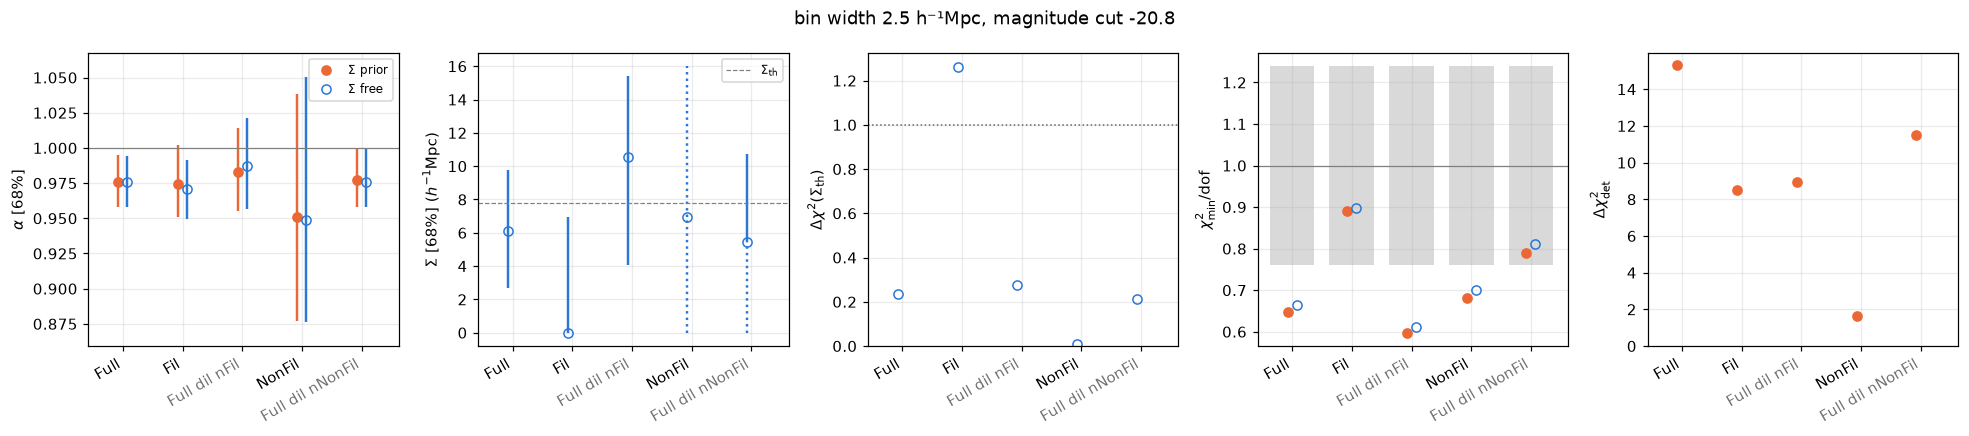

In [16]:
def draw_interval(ax, x, v, lo, hi, color, filled, edge_lo, edge_hi, label=None):
    # point with its 68% interval; a side that reaches a prior edge (nan in the table) is dotted up to edge_lo / edge_hi
    ax.plot(x, v, 'o', color=color, mfc=color if filled else 'none', label=label)
    for end, edge in ((lo, edge_lo), (hi, edge_hi)):
        ok = np.isfinite(end)
        ax.vlines(x, *sorted((v, end if ok else edge)), color=color, ls='-' if ok else ':')

# all samples, each random dilution right after the sample whose N it matches
labs_6 = []
for lab in labs:
    if lab.startswith('Full dil'): continue
    labs_6 += [lab] + [d for d in (f'Full dil n{lab}',) if d in res]
x = np.arange(len(labs_6)); dx = 0.15
fig, axes = plt.subplots(1, 5, figsize=(18, 4))
aA, aS, aT, aC, aD = axes

# alpha: open sides are dotted to the edge of the panel, whose range is set by the finite values
fin = [v for lab in labs_6 for k in ('fit', 'fit_S')
       for v in (res[lab][k]['pars']['qiso'], res[lab][k]['lo'], res[lab][k]['hi']) if np.isfinite(v)] + [1.0]
pad = 0.1 * (max(fin) - min(fin)); ylo, yhi = min(fin) - pad, max(fin) + pad
for j, lab in enumerate(labs_6):
    f, fS = res[lab]['fit'], res[lab]['fit_S']
    draw_interval(aA, j, f['pars']['qiso'], f['lo'], f['hi'], DESI, True, ylo, yhi,
                  label='Σ prior' if j == 0 else None)
    draw_interval(aA, j + dx, fS['pars']['qiso'], fS['lo'], fS['hi'], FREE, False, ylo, yhi,
                  label='Σ free' if j == 0 else None)
aA.set_ylim(ylo, yhi); aA.axhline(1, color='0.5', lw=0.8)
aA.set_ylabel(r'$\alpha$ [68%]'); aA.legend(fontsize=8)

# Sigma (Sigma fit, flat prior): sides at the edge of Sigma_free are dotted up to that edge
for j, lab in enumerate(labs_6):
    fS, pS = res[lab]['fit_S'], res[lab]['prof_Sig']
    draw_interval(aS, j, fS['pars']['sigmaper'], pS['lo'], pS['hi'], FREE, False, *Sigma_free)
aS.axhline(Sigma_th, color='0.5', ls='--', lw=0.8, label=r'$\Sigma_{\rm th}$')
aS.set_ylabel(r'$\Sigma$ [68%] ($h^{-1}$Mpc)'); aS.legend(fontsize=8)

# Delta chi2 at Sigma_th (above 1: Sigma_th outside the 68% interval of Sigma)
aT.plot(x, [res[lab]['prof_Sig']['dchi2_th'] for lab in labs_6], 'o', color=FREE, mfc='none')
aT.axhline(1, color='0.4', ls=':', lw=1); aT.set_ylim(bottom=0)
aT.set_ylabel(r'$\Delta\chi^2(\Sigma_{\rm th})$')

# chi2/dof of both fits; grey: expected 1 +- sqrt(2/dof) of each sample's alpha fit
for j, lab in enumerate(labs_6):
    r = res[lab]
    e = np.sqrt(2 / r['dof'])
    aC.fill_between([j - 0.3, j + 0.3 + dx], 1 - e, 1 + e, color='0.85', lw=0)
    aC.plot(j, r['chi2'] / r['dof'], 'o', color=DESI)
    aC.plot(j + dx, r['fit_S']['chi2'] / r['dof_S'], 'o', color=FREE, mfc='none')
aC.axhline(1, color='0.5', lw=0.8)
aC.set_ylabel(r'$\chi^2_{\rm min}/{\rm dof}$')

# detection
aD.plot(x, [res[lab]['det'] for lab in labs_6], 'o', color=DESI)
aD.set_ylim(bottom=0); aD.set_ylabel(r'$\Delta\chi^2_{\rm det}$')

for a in axes:
    a.set_xticks(x + dx / 2); a.set_xticklabels(labs_6, rotation=30, ha='right'); a.set_xlim(-0.5, len(labs_6) - 0.3)
    for t in a.get_xticklabels():
        if t.get_text().startswith('Full dil'): t.set_color('0.45')
fig.suptitle(f'bin width {binsep:g} h⁻¹Mpc, magnitude cut {mag}'); fig.tight_layout(); plt.show()

## 7. Differences between samples: Δα and ΔΣ

For each pair (A, B) in `pairs` (settings cell), Δα = α_A − α_B and ΔΣ = Σ_A − Σ_B. The two samples come from the
same box and partly share galaxies, so their noise is correlated and the error of a difference is not
$\sqrt{\sigma_A^2+\sigma_B^2}$. Both samples are therefore fitted at once, with their joint covariance:

$$
\chi^2=(\mathbf d-\mathbf m)^{\rm T}\,\mathsf C^{-1}(\mathbf d-\mathbf m),\qquad
\mathbf d=\begin{pmatrix}\hat\xi_{0,A}\\ \hat\xi_{0,B}\end{pmatrix},\qquad
\mathsf C=\begin{pmatrix}\mathsf C_{AA}&\mathsf C_{AB}\\ \mathsf C_{BA}&\mathsf C_{BB}\end{pmatrix}
$$

where $\hat\xi_{0,A}$, $\hat\xi_{0,B}$ are the two monopoles in the fit range, $\mathbf m$ the two models, and $\mathsf C$
is `bf.gaussian_cov_pk` for both samples together: the diagonal blocks are the covariances of the single fits,
and the cross block $\mathsf C_{AB}$ is built in the same way from the measured cross power spectrum $P_{AB}(k)$ (which
contains the shot noise of the galaxies the two samples share).

Each sample keeps its own parameters (α, Σ, $b_1$ and the broadband), with the same model as the single fits,
except that sample B's parameter of interest is written through the difference:

* **Δα:** $\alpha_B=\alpha_A-\Delta\alpha$, with the Gaussian Σ prior of the α fit on each sample (the χ² includes the
  two prior terms).
* **ΔΣ:** $\Sigma_B=\Sigma_A-\Delta\Sigma$, with the flat prior `Sigma_free` on both Σ (so $\Sigma_A\ge0$ and $\Sigma_B\ge0$).

For each difference Δ the cell computes the best fit (Δ free) and the profile

$$
\boxed{\;\Delta\chi^2(\Delta)=\chi^2_{\rm prof}(\Delta)-\chi^2_{\rm min}\;}
$$

where $\chi^2_{\rm prof}(\Delta)$ is the minimum of χ² with Δ fixed and all other parameters of both samples refitted, on
a grid set in the settings cell (plus 0 and the best fit), and $\chi^2_{\rm min}$ its smallest value. As for α and Σ:

* **Δ [68%]**: best fit and the interval where Δχ²(Δ) ≤ 1 (`edge`: the interval reaches the end of the grid);
* **Δχ²(0)**: the cost of forcing the two samples to the same value. For a Gaussian likelihood, $\sqrt{\Delta\chi^2(0)}$
  is the significance of the difference in σ; near the Σ = 0 edge this holds only approximately.

**How it is computed.** The model of each sample is `desilike_lik`'s, exactly as in the single fits; the joint χ²
above (plus the two Gaussian Σ prior terms for Δα) is written out in the cell and minimised with iminuit, the
minimiser desilike's `MinuitProfiler` uses. (desilike's own joint likelihood is not used: with two separate α in
one pipeline it does not set $\Sigma_\parallel=\Sigma_\perp$ for the second sample.) The fits start from the single-fit
best values (section 2), so section 2 must have been run. All limits of the single fits hold for both samples:
α in 0.8–1.2, Σ in `Sigma_free` (0–30 h⁻¹Mpc in the Δα fits); for B through the tie.

The best-fit Δα and ΔΣ need not equal the differences of the single-fit values (section 5): the joint fit also
uses the cross covariance. Each profile is a few dozen joint fits, so this section takes a while.

Fil - Full dil nFil        Delta alpha = -0.0034   Delta Sigma = -7.46   (66 s)
NonFil - Full dil nNonFil  Delta alpha = -0.0271   Delta Sigma = +1.30   (119 s)
Fil - NonFil               Delta alpha = +0.0217   Delta Sigma = -7.07   (164 s)
Fil - Full                 Delta alpha = -0.0013   Delta Sigma = -6.61   (233 s)
NonFil - Full              Delta alpha = -0.0286   Delta Sigma = +0.49   (288 s)

bin width 2.5 h^-1 Mpc, magnitude cut -20.8
A - B                     | Delta alpha [68%]           | dchi2(0) | Delta Sigma [68%]       | dchi2(0)
-------------------------------------------------------------------------------------------------------
Fil - Full dil nFil       | -0.0034 [-0.0273, +0.0200]  |     0.02 | -7.46 [-14.40, -2.78]   |     2.54
NonFil - Full dil nNonFil | -0.0271 [-0.1058, +0.0636]  |     0.12 | +1.30 [-10.39, +13.80]  |     0.01
Fil - NonFil              | +0.0217 [-0.0669, +0.1007]  |     0.08 | -7.07 [edge, +6.15]     |     0.18
Fil - Full                | -0.

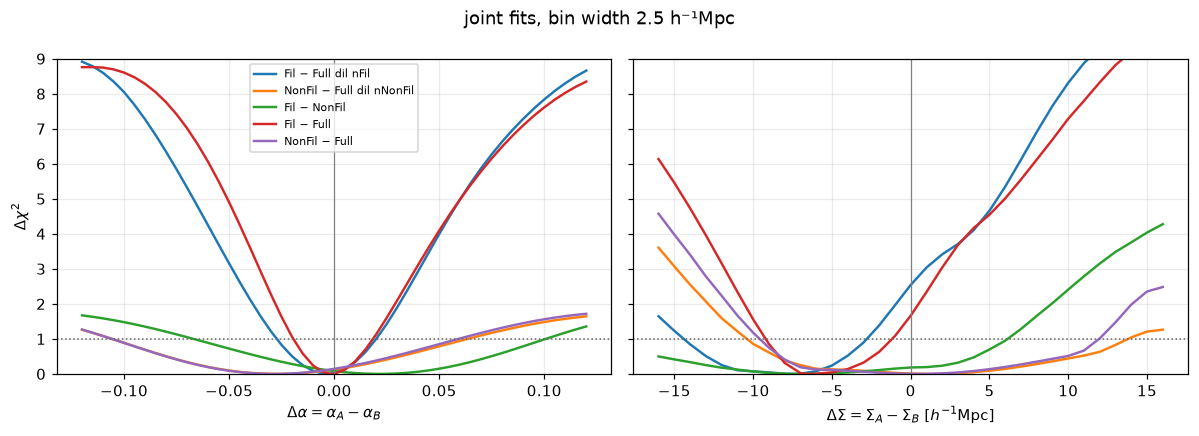

In [15]:
from iminuit import Minuit

def joint_setup(A, B, tie):
    # joint chi2 of samples A and B for tie = 'alpha' (alpha_B = alpha_A - Delta, Gaussian Sigma priors of the
    # alpha fit) or 'Sigma' (Sigma_B = Sigma_A - Delta, flat priors Sigma_free).  The models are desilike_lik's,
    # i.e. exactly those of the single fits; only the chi2 is joint.
    dA, dB = data[A], data[B]
    assert np.allclose(dA['edges'], dB['edges']) and np.array_equal(dA['m'], dB['m']), f"{A}, {B}: different bins"
    nb = len(dA['s'])
    Cj = bf.gaussian_cov_pk(dA['edges'], spec, [spec['labels'].index(samples[A]), spec['labels'].index(samples[B])],
                            [dA['b'], dB['b']], lin)
    idx = np.concatenate([np.nonzero(dA['m'])[0], nb + np.nonzero(dB['m'])[0]])
    Cinv = np.linalg.inv(Cj[np.ix_(idx, idx)])
    dvec = np.concatenate([dA['xi'][dA['m']], dB['xi'][dB['m']]])
    model = {X: desilike_lik(data[X], 'gauss' if tie == 'alpha' else 'flat') for X in (A, B)}
    pnames = [p.name for p in model[A][0].varied_params]           # per-sample parameters (same for A and B)
    key = {'alpha': 'qiso', 'Sigma': 'sigmaper'}[tie]

    def chi2(pA, pB):
        r = []
        for X, p in ((A, pA), (B, pB)):
            lik, obs = model[X]; lik(**p); r.append(np.array(obs.flattheory))
        r = dvec - np.concatenate(r)
        c = r @ Cinv @ r
        if tie == 'alpha':                                           # the Gaussian Sigma prior on each sample
            c += sum(((p['sigmaper'] - Sigma_th) / Sigma_prior_sd)**2 for p in (pA, pB))
        return float(c)

    # free parameters: A's, B's except the tied one, and Delta; start from the single fits (section 2)
    start = {f'A {n}': v for n, v in res[A]['fit' if tie == 'alpha' else 'fit_S']['pars'].items()}
    start.update({f'B {n}': v for n, v in res[B]['fit' if tie == 'alpha' else 'fit_S']['pars'].items() if n != key})
    start['Delta'] = start[f'A {key}'] - res[B]['fit' if tie == 'alpha' else 'fit_S']['pars'][key]
    names = list(start)

    def fcn(*x):
        v = dict(zip(names, x))
        pA = {n: v[f'A {n}'] for n in pnames}
        pB = {n: (v[f'A {key}'] - v['Delta'] if n == key else v[f'B {n}']) for n in pnames}
        return chi2(pA, pB)

    # limits: alpha in (0.8, 1.2) and Sigma in Sigma_free (alpha fit: (0, 30)) for BOTH samples, through the tie
    lim = {'qiso': (0.8, 1.2), 'sigmaper': Sigma_free if tie == 'Sigma' else (0., 30.)}

    def minimise(delta=None):
        m = Minuit(fcn, *[start[n] for n in names], name=names)
        m.errordef = Minuit.LEAST_SQUARES
        for n in pnames:
            if n in lim:
                m.limits[f'A {n}'] = lim[n]
                if n != key: m.limits[f'B {n}'] = lim[n]
        lo, hi = lim[key]
        if delta is None:
            m.limits['Delta'] = (lo - hi, hi - lo)
        else:                                                        # Delta fixed: keep B's tied parameter in range
            m.values['Delta'] = delta; m.fixed['Delta'] = True
            m.limits[f'A {key}'] = (max(lo, lo + delta), min(hi, hi + delta))
            m.values[f'A {key}'] = np.clip(m.values[f'A {key}'], *m.limits[f'A {key}'])
        m.migrad()
        if not m.valid: m.migrad()
        start.update(zip(names, m.values))                           # warm start for the next grid point
        return m.fval, float(m.values['Delta'])
    return minimise

def delta_profile(A, B, tie, grid):
    # best fit of Delta, profile Delta chi2 on the grid (+ 0 and the best fit), 68% interval
    minimise = joint_setup(A, B, tie)
    chi2_best, best = minimise()
    x = np.union1d(grid, [0., best])
    x = x[(x >= grid[0]) & (x <= grid[-1]) | np.isclose(x, best)]
    i0 = int(np.argmin(np.abs(x - best)))
    c = np.full(len(x), np.nan)
    for order in (range(i0, len(x)), range(i0 - 1, -1, -1)):         # walk out from the best fit (warm starts)
        minimise(best)
        for i in order:
            c[i] = minimise(x[i])[0]
    dchi2 = c - min(c.min(), chi2_best)
    lo, hi = interval_68(x, dchi2)
    return dict(best=best, x=x, dchi2=dchi2, lo=lo, hi=hi, dchi2_0=float(dchi2[np.argmin(np.abs(x))]))

grids = {'alpha': np.arange(-dalpha_max, dalpha_max + 1e-9, dalpha_step),
         'Sigma': np.arange(-Sigma_free[1], Sigma_free[1] + 1e-9, dSigma_step)}
diff = {}
t0 = time.time()
for A, B in pairs:
    if A not in data or B not in data:
        print(f"SKIP {A} - {B}: sample not loaded"); continue
    diff[(A, B)] = {tie: delta_profile(A, B, tie, grids[tie]) for tie in ('alpha', 'Sigma')}
    r = diff[(A, B)]
    print(f"{A + ' - ' + B:<26} Delta alpha = {r['alpha']['best']:+.4f}   Delta Sigma = {r['Sigma']['best']:+.2f}   "
          f"({time.time() - t0:.0f} s)")

def fmt_d(r, f):
    g = lambda x: 'edge' if not np.isfinite(x) else format(x, f)
    return f"{format(r['best'], f)} [{g(r['lo'])}, {g(r['hi'])}]"

hdr = f"{'A - B':<26}| {'Delta alpha [68%]':<28}| {'dchi2(0)':>8} | {'Delta Sigma [68%]':<24}| {'dchi2(0)':>8}"
print(f"\nbin width {binsep:g} h^-1 Mpc, magnitude cut {mag}"); print(hdr); print('-' * len(hdr))
for (A, B), r in diff.items():
    print(f"{A + ' - ' + B:<26}| {fmt_d(r['alpha'], '+.4f'):<28}| {r['alpha']['dchi2_0']:>8.2f} | "
          f"{fmt_d(r['Sigma'], '+.2f'):<24}| {r['Sigma']['dchi2_0']:>8.2f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for (A, B), r in diff.items():
    for ax, tie in zip(axes, ('alpha', 'Sigma')):
        ax.plot(r[tie]['x'], r[tie]['dchi2'], label=f"{A} − {B}")
for ax, xl in zip(axes, (r'$\Delta\alpha=\alpha_A-\alpha_B$', r'$\Delta\Sigma=\Sigma_A-\Sigma_B\ [h^{-1}{\rm Mpc}]$')):
    ax.axhline(1, color='0.4', ls=':', lw=1); ax.axvline(0, color='0.5', lw=0.8)
    ax.set_xlabel(xl); ax.set_ylim(0, 9)
axes[0].set_ylabel(r'$\Delta\chi^2$'); axes[0].legend(fontsize=7)
fig.suptitle(f'joint fits, bin width {binsep:g} h⁻¹Mpc'); fig.tight_layout(); plt.show()